# GoTyme Case Study: Cold-Call Response Model
**End-to-end build, mentor-guided.** Objective: classify whether a customer will take up a sales offer on a cold call, then overlay revenue/cost to estimate campaign profit.

| Stage | Topic |
|---|---|
| 1 | Data understanding & cleaning |
| 2 | Feature relevance, discriminating power, correlation |
| 3 | Preparation: encoding, grouping, binning, scaling, imbalance |
| 4 | Modelling & validation |
| 5 | Tuning, importance, cut-off |
| 6 | Bonus: campaign profit & lost opportunity |

> **How to use:** run top to bottom. Each stage ends with *Decisions* and *Interview talking points*, written so you can say them out loud.

In [3]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

DATA_PATH = r'C:\Users\Vernon\Desktop\CodingWorkSpace\GoTyme_caseStudy\dataset.csv'   # <- change to your local path
SEED = 42
TARGET = 'Response'
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid', context='notebook')

---
# Stage 1: Data understanding & cleaning
*Case questions:* "Explain what your data looks like", "Are there outliers or corrections?", "Are all inputs relevant?"

In [4]:
raw = pd.read_csv(DATA_PATH, sep='|')          # file is pipe-delimited
raw.columns = raw.columns.str.strip()           # data dictionary has leading spaces
print('Shape:', raw.shape)
print('Missing values:', int(raw.isna().sum().sum()))
print('Exact duplicate rows:', int(raw.duplicated().sum()))
raw.head()

Shape: (35000, 21)
Missing values: 0
Exact duplicate rows: 11


,Feature_ae_0,Feature_dn_1,Feature_cn_2,Feature_ps_3,Feature_ps_4,Feature_ee_5,Feature_cx_6,Feature_cx_7,Feature_em_8,Feature_nd_9,Feature_jd_10,Feature_md_11,Feature_ed_12,Feature_dd_13,Feature_hd_14,Feature_ld_15,Feature_cd_16,Feature_md_17,Feature_dd_18,Feature_pd_19,Response
0,57,371,1,999,1,-1.8,92.893,-46.2,1.299,5099.1,Cat_9_t***n,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_0_n***o,Cat_2_y***s,Cat_0_c***r,Cat_6_m***y,Cat_1_m***n,Cat_0_f***e,0
1,55,285,2,999,0,1.1,93.994,-36.4,4.860,5191.0,Cat_11_u***n,Cat_1_m***d,Cat_7_u***n,Cat_1_u***n,Cat_2_y***s,Cat_0_n***o,Cat_1_t***e,Cat_6_m***y,Cat_2_t***u,Cat_1_n***t,0
2,33,52,1,999,1,-1.8,92.893,-46.2,1.313,5099.1,Cat_1_b***r,Cat_1_m***d,Cat_2_b***y,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_0_c***r,Cat_6_m***y,Cat_0_f***i,Cat_0_f***e,0
3,36,355,4,999,0,1.4,94.465,-41.8,4.967,5228.1,Cat_0_a***.,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_1_t***e,Cat_4_j***n,Cat_0_f***i,Cat_1_n***t,0
4,27,189,2,999,0,1.4,93.918,-42.7,4.963,5228.1,Cat_3_h***d,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_3_j***l,Cat_0_f***i,Cat_1_n***t,0


In [5]:
NUM = [c for c in raw.columns if pd.api.types.is_numeric_dtype(raw[c]) and c != TARGET]
CAT = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
print(len(NUM), 'numeric;', len(CAT), 'categorical')
raw[NUM].describe(percentiles=[.01,.25,.5,.75,.99]).T.round(2)

10 numeric; 10 categorical


,count,mean,std,min,1%,25%,50%,75%,99%,max
Feature_ae_0,35000.0,40.03,10.43,17.00,23.00,32.00,38.00,47.00,71.00,98.00
Feature_dn_1,35000.0,257.84,258.59,0.00,11.00,102.00,179.00,318.00,1268.00,4918.00
Feature_cn_2,35000.0,2.56,2.77,1.00,1.00,1.00,2.00,3.00,14.00,56.00
Feature_ps_3,35000.0,962.43,187.01,0.00,3.00,999.00,999.00,999.00,999.00,999.00
Feature_ps_4,35000.0,0.17,0.50,0.00,0.00,0.00,0.00,0.00,2.00,7.00
Feature_ee_5,35000.0,0.08,1.57,-3.40,-3.40,-1.80,1.10,1.40,1.40,1.40
Feature_cx_6,35000.0,93.58,0.58,92.20,92.20,93.08,93.75,93.99,94.46,94.77
Feature_cx_7,35000.0,-40.52,4.62,-50.80,-49.50,-42.70,-41.80,-36.40,-26.90,-26.90
Feature_em_8,35000.0,3.62,1.73,0.63,0.66,1.34,4.86,4.96,4.97,5.04
Feature_nd_9,35000.0,5167.04,72.17,4963.60,4963.60,5099.10,5191.00,5228.10,5228.10,5228.10


### 1.1 Target balance
Only ~1 in 9 customers says yes. Accuracy is therefore a poor metric (always predicting "no" scores ~89%).

In [6]:
print(raw[TARGET].value_counts(normalize=True).round(4))
print('Naive "always No" accuracy:', round(1-raw[TARGET].mean(),4))

Response
0    0.8877
1    0.1123
Name: proportion, dtype: float64
Naive "always No" accuracy: 0.8877


### 1.2 Categorical levels (incl. rare levels and 'unknown')

In [7]:
for c in CAT:
    vc = raw[c].value_counts()
    print(f'\n{c}  ({len(vc)} levels)')
    print(pd.DataFrame({'n':vc,'pct':(vc/len(raw)*100).round(2),'resp_rate':raw.groupby(c)[TARGET].mean().reindex(vc.index).round(3)}).to_string())


Feature_jd_10  (12 levels)
                  n    pct  resp_rate
Feature_jd_10                        
Cat_0_a***.    8866  25.33      0.130
Cat_1_b***r    7858  22.45      0.070
Cat_9_t***n    5737  16.39      0.108
Cat_7_s***s    3353   9.58      0.077
Cat_4_m***t    2489   7.11      0.113
Cat_5_r***d    1466   4.19      0.254
Cat_2_e***r    1256   3.59      0.083
Cat_6_s***d    1215   3.47      0.102
Cat_3_h***d     901   2.57      0.107
Cat_10_u***d    839   2.40      0.143
Cat_8_s***t     727   2.08      0.318
Cat_11_u***n    293   0.84      0.102

Feature_md_11  (4 levels)
                   n    pct  resp_rate
Feature_md_11                         
Cat_1_m***d    21212  60.61      0.101
Cat_2_s***e     9816  28.05      0.140
Cat_0_d***d     3903  11.15      0.102
Cat_3_u***n       69   0.20      0.159

Feature_ed_12  (8 levels)
                   n    pct  resp_rate
Feature_ed_12                         
Cat_6_u***e    10312  29.46      0.136
Cat_3_h***l     8042  22.98      0.

### 1.3 The 999 sentinel in `Feature_ps_3`
"999 = no previous campaign" is a **code, not a number**. Treating it as a number would make "never contacted" look like "contacted 999 days ago".

In [8]:
print('Share of 999:', round((raw.Feature_ps_3==999).mean(),4))
print(raw.loc[raw.Feature_ps_3<999,'Feature_ps_3'].describe().round(1))

Share of 999: 0.9632
count    1289.0
mean        6.1
std         3.9
min         0.0
25%         3.0
50%         6.0
75%         7.0
max        27.0
Name: Feature_ps_3, dtype: float64


### 1.4 The leakage trap: `Feature_dn_1` (call duration)
The data dictionary says it is *"only known after call has taken place"*. Ask the test question: **would I have this value when I decide whom to dial?** No, so it cannot be a production feature.

,customers,response_rate
Feature_dn_1,,
0,4,0.000
1-100,8509,0.008
101-300,16993,0.071
301-600,6555,0.184
>600,2939,0.491


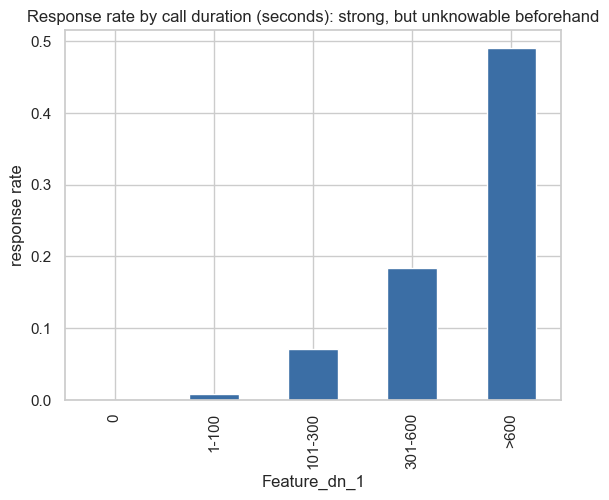

In [9]:
band = pd.cut(raw.Feature_dn_1,[-1,0,100,300,600,5000],labels=['0','1-100','101-300','301-600','>600'])
t = raw.groupby(band).agg(customers=(TARGET,'size'), response_rate=(TARGET,'mean')).round(3); display(t)
t.response_rate.plot.bar(color='#3b6ea5', title='Response rate by call duration (seconds): strong, but unknowable beforehand'); plt.ylabel('response rate'); plt.show()

### 1.5 Distributions & outliers

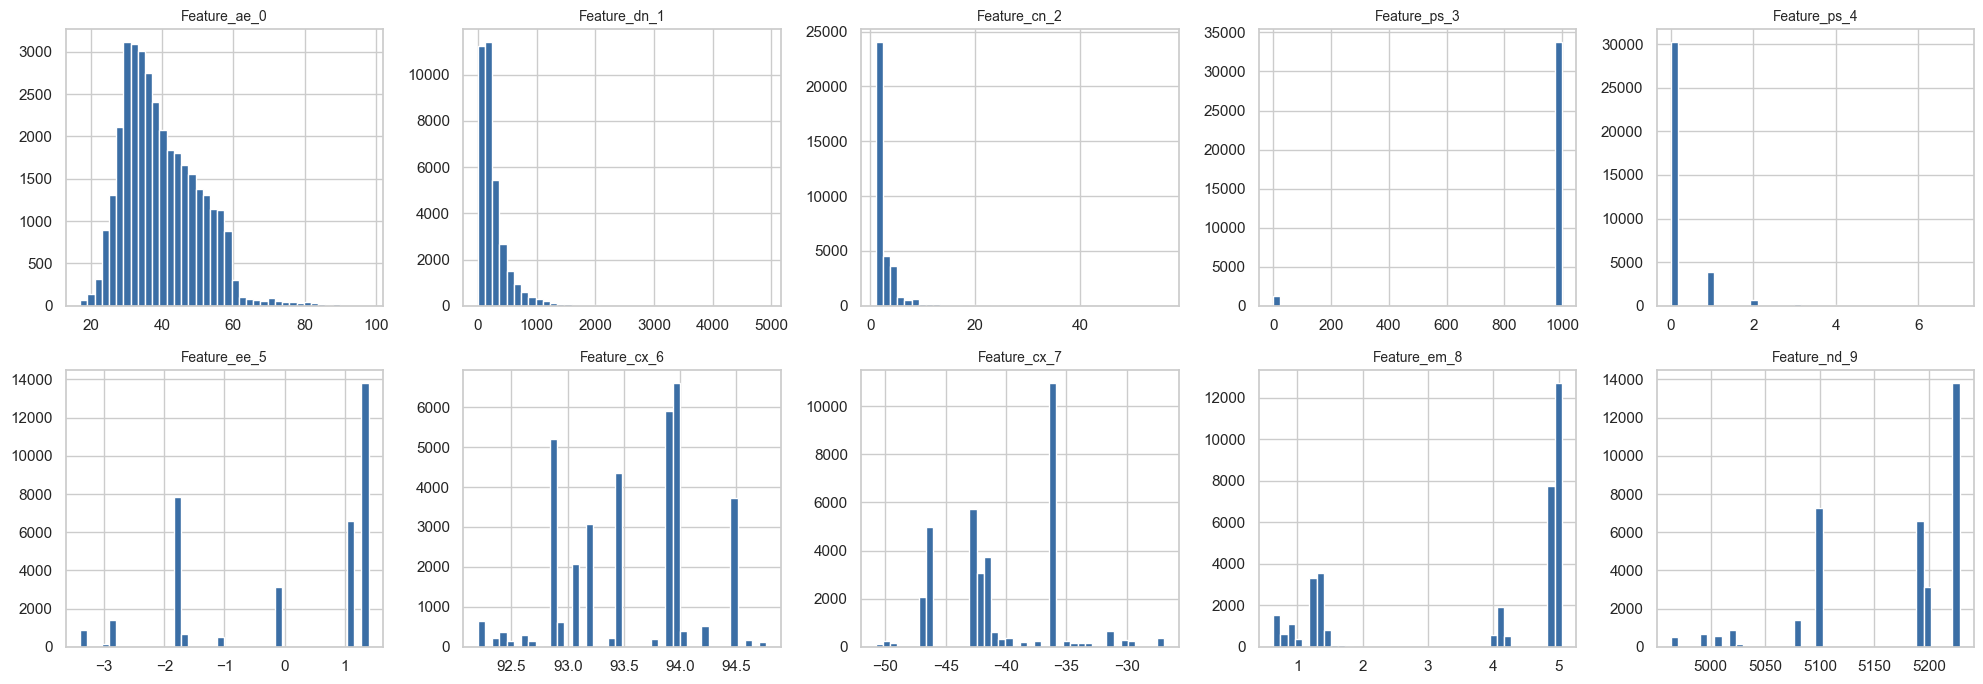

In [10]:
fig, ax = plt.subplots(2,5, figsize=(20,7))
for a,c in zip(ax.ravel(), NUM):
    a.hist(raw[c], bins=40, color='#3b6ea5'); a.set_title(c, fontsize=10)
plt.tight_layout(); plt.show()

In [11]:
rows=[]
for c in ['Feature_ae_0','Feature_dn_1','Feature_cn_2','Feature_ps_4']:
    q1,q3 = raw[c].quantile([.25,.75]); fence = q3+1.5*(q3-q1)
    rows.append((c, raw[c].max(), raw[c].quantile(.99), fence, int((raw[c]>fence).sum())))
display(pd.DataFrame(rows, columns=['var','max','p99','IQR upper fence','n above fence']).round(1))
print('\nCustomers with >20 call attempts:', int((raw.Feature_cn_2>20).sum()), '| their response rate:', raw.loc[raw.Feature_cn_2>20, TARGET].mean())

,var,max,p99,IQR upper fence,n above fence
0,Feature_ae_0,98,71.0,69.5,402
1,Feature_dn_1,4918,1268.0,642.0,2534
2,Feature_cn_2,56,14.0,6.0,2036
3,Feature_ps_4,7,2.0,0.0,4808



Customers with >20 call attempts: 134 | their response rate: 0.007462686567164179


### Stage 1: Decisions
| Finding | Decision | Why |
|---|---|---|
| 11 duplicate rows | Drop | Negligible, avoids double-counting |
| No missing values; "unknown" is a category | Keep as its own level | Unknown can carry signal (non-random) |
| `ps_3` 999 sentinel (96%) | Replace with flag `prev_contacted`; keep days only for contacted | Sentinel is a code, not a quantity |
| `dn_1` call duration | **Exclude** from production model | Leakage: unknown at decision time |
| `cn_2` extreme counts (max 43) | Cap (e.g. at 10) | Few rows, 0% response beyond 20, limits leverage |
| Age > 70 (~1%) | Keep | Real customers, not errors |
| Rare levels (3 default="yes", 17 "illiterate", 69 marital "unknown") | Group in Stage 3 | Too few rows to estimate reliably |



---
# Stage 2: Feature relevance, discriminating power, correlation
*Case questions:* "How do you check for discriminating power?", "How do you control for high correlations?", "Do you care whether classes are balanced?"

### 2.1 Split FIRST
Variable selection uses the target, so it must be done on **training data only**. Otherwise the test set leaks into feature choice and the test score is flattered. We use a stratified 70/30 split so both parts keep the 11.2% response rate.

In [12]:
df = raw.drop_duplicates().reset_index(drop=True)
train, test = train_test_split(df, test_size=0.30, stratify=df[TARGET], random_state=SEED)
print(f'train={len(train):,} test={len(test):,} | response rate train={train[TARGET].mean():.4f} test={test[TARGET].mean():.4f}')
y = train[TARGET]

train=24,492 test=10,497 | response rate train=0.1123 test=0.1123


### 2.2 Information Value (IV) & Weight of Evidence (WoE)
For each bin: WoE = ln(%non-responders / %responders); IV = Σ (%non − %resp) × WoE.  
| IV | Reading |
|---|---|
| < 0.02 | useless |
| 0.02-0.1 | weak |
| 0.1-0.3 | medium |
| 0.3-0.5 | strong |
| > 0.5 | suspiciously strong: check for leakage |

Numeric variables are binned into deciles first. Variables with few distinct values (e.g. 96% at 999) need special handling, so `ps_3` is converted to a flag first.

In [13]:
def iv(x, y):
    t = pd.DataFrame({'x':x,'y':y}).groupby('x').y.agg(['sum','count']); t['n']=t['count']-t['sum']; t=t+0.5   # smoothing avoids log(0)
    pn, pr = t['n']/t['n'].sum(), t['sum']/t['sum'].sum()
    return float(((pn-pr)*np.log(pn/pr)).sum())

tr = train.copy()
tr['ps3_prev_contacted'] = (tr.Feature_ps_3<999).astype(int)
num_for_iv = [c for c in NUM if c!='Feature_ps_3']
res=[]
for c in num_for_iv:
    res.append((c,'numeric',iv(pd.qcut(tr[c],10,duplicates='drop'),y), roc_auc_score(y,tr[c])))
for c in CAT: res.append((c,'categorical',iv(tr[c],y),np.nan))
res.append(('ps3_prev_contacted (from Feature_ps_3)','flag',iv(tr.ps3_prev_contacted,y),roc_auc_score(y,tr.ps3_prev_contacted)))
ivt = pd.DataFrame(res,columns=['variable','type','IV','univariate_AUC']).sort_values('IV',ascending=False).reset_index(drop=True)
ivt['tier'] = pd.cut(ivt.IV,[-1,.02,.1,.3,.5,99],labels=['useless','weak','medium','strong','very strong / check leakage'])
display(ivt.round(3))

,variable,type,IV,univariate_AUC,tier
0,Feature_dn_1,numeric,1.934,0.823,very strong / check leakage
1,Feature_nd_9,numeric,1.114,0.258,very strong / check leakage
2,Feature_em_8,numeric,0.991,0.264,very strong / check leakage
3,Feature_ee_5,numeric,0.746,0.291,very strong / check leakage
4,Feature_cx_7,numeric,0.740,0.534,very strong / check leakage
5,ps3_prev_contacted (from Feature_ps_3),flag,0.545,0.596,very strong / check leakage
6,Feature_pd_19,categorical,0.543,NaN,very strong / check leakage
7,Feature_md_17,categorical,0.477,NaN,strong
8,Feature_cx_6,numeric,0.469,0.397,strong
9,Feature_cd_16,categorical,0.241,NaN,medium


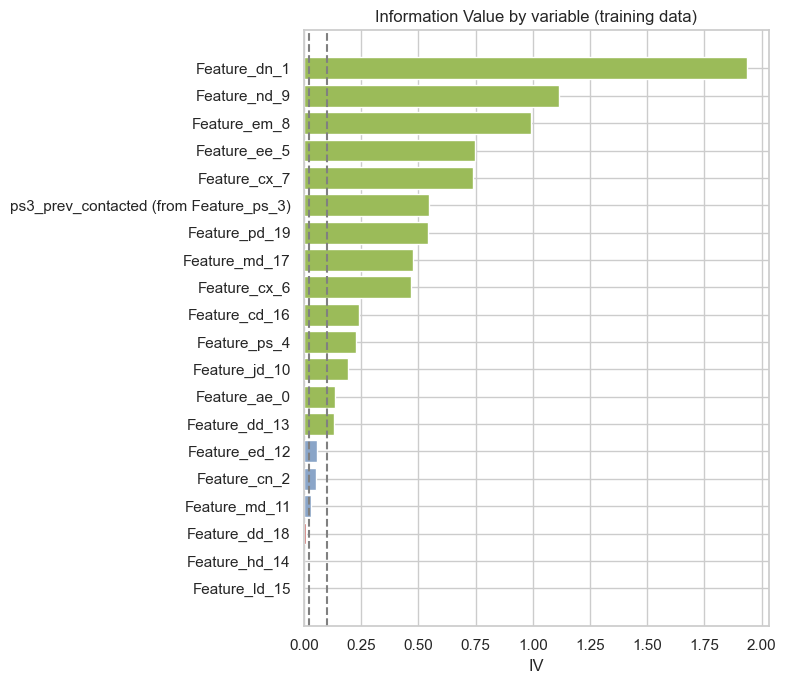

In [14]:
p = ivt.sort_values('IV'); colors = p.IV.map(lambda v:'#c0504d' if v<.02 else '#9bbb59' if v>=.1 else '#8aa5c8')
plt.figure(figsize=(8,7)); plt.barh(p.variable, p.IV, color=colors); plt.axvline(.02,ls='--',c='grey'); plt.axvline(.1,ls='--',c='grey')
plt.title('Information Value by variable (training data)'); plt.xlabel('IV'); plt.tight_layout(); plt.show()

**Two cautions to say out loud**
1. `Feature_ps_3` scored IV≈0 if binned naively (96% of values identical) but **0.55** as a flag, so *how you treat a variable decides its apparent power*.
2. The macro variables have huge IV but few distinct values: they mostly encode *when* the call happened (economic cycle). Strong in-sample, but a generalisation risk if conditions change.

### 2.3 Correlation and multicollinearity

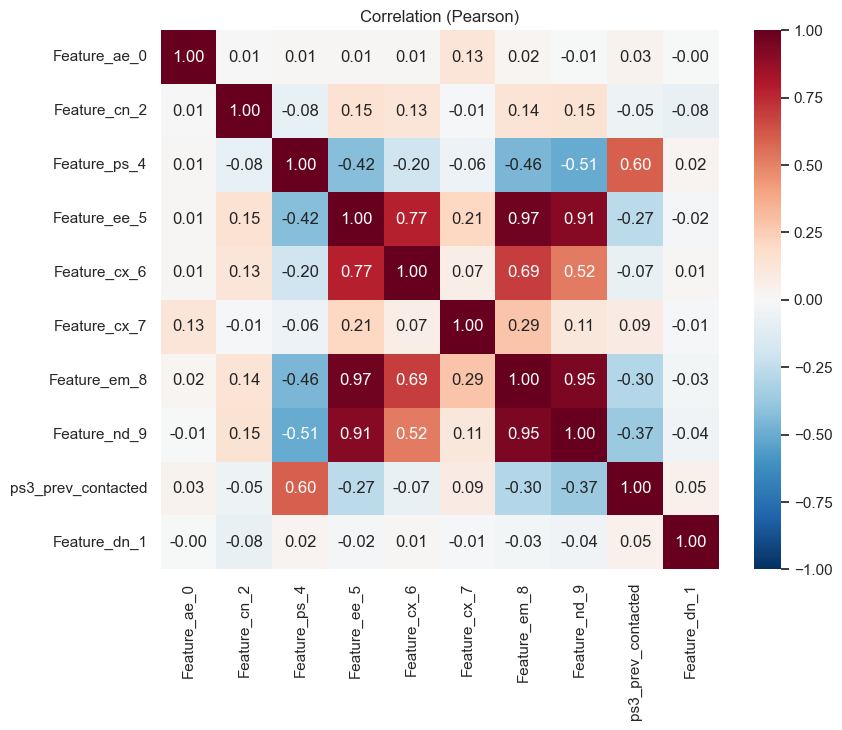

In [15]:
numc = ['Feature_ae_0','Feature_cn_2','Feature_ps_4','Feature_ee_5','Feature_cx_6','Feature_cx_7','Feature_em_8','Feature_nd_9','ps3_prev_contacted']
plt.figure(figsize=(9,7)); sns.heatmap(tr[numc+['Feature_dn_1']].corr(),annot=True,fmt='.2f',cmap='RdBu_r',center=0,vmin=-1,vmax=1); plt.title('Correlation (Pearson)'); plt.show()

In [16]:
def vif_table(cols):
    X = tr[cols].astype(float); X = (X-X.mean())/X.std(); X['const']=1.0
    return pd.Series([variance_inflation_factor(X.values,i) for i in range(len(cols))], index=cols).round(1)
vif_all = vif_table(numc)
vif_reduced = vif_table([c for c in numc if c not in ('Feature_ee_5','Feature_nd_9')])
display(pd.DataFrame({'VIF (all)':vif_all,'VIF (keep em_8 only of the 3)':vif_reduced}))

,VIF (all),VIF (keep em_8 only of the 3)
Feature_ae_0,1.0,1.0
Feature_cn_2,1.0,1.0
Feature_cx_6,6.3,2.1
Feature_cx_7,2.6,1.2
Feature_ee_5,32.7,NaN
Feature_em_8,64.0,2.8
Feature_nd_9,31.6,NaN
Feature_ps_4,1.8,1.8
ps3_prev_contacted,1.6,1.6


**Reading VIF:** above 5-10 means a variable is largely predictable from the others. `ee_5`, `em_8`, `nd_9` have VIFs of ~30-65, being essentially one variable (corr 0.91-0.97). In logistic regression this makes coefficients unstable and uninterpretable (signs can flip). Trees are less affected for prediction but importance gets split arbitrarily between the twins.  
**Action:** keep exactly one of the three (which one is decided empirically in Stage 3.6). Illustrated here with `em_8`, the VIFs of everything left drop below 3.

### 2.4 Leakage test: how much does call duration inflate the model?

,Test AUC
All 20 features (incl. duration),0.935
Without call duration,0.802
Without duration & call attempts,0.801


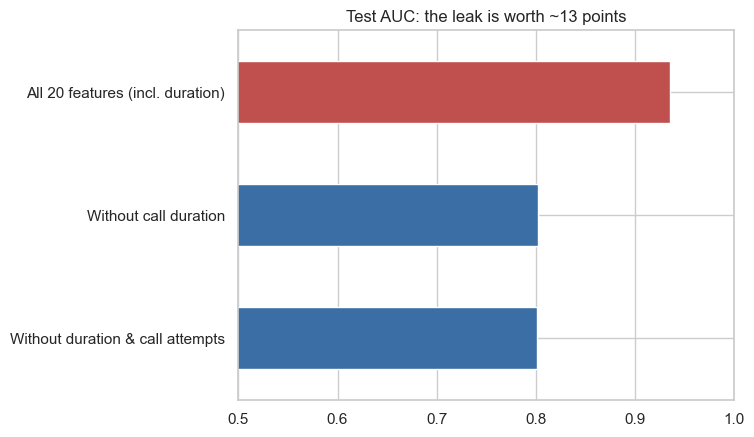

In [17]:
def quick_auc(cols):
    A = pd.get_dummies(train[cols],drop_first=True).astype(float)
    B = pd.get_dummies(test[cols],drop_first=True).astype(float).reindex(columns=A.columns,fill_value=0)
    m,s = A.mean(),A.std().replace(0,1)
    lr = LogisticRegression(max_iter=3000).fit((A-m)/s,train[TARGET])
    return roc_auc_score(test[TARGET], lr.predict_proba((B-m)/s)[:,1])
feats = [c for c in df.columns if c!=TARGET]
out = pd.Series({'All 20 features (incl. duration)':quick_auc(feats),
                 'Without call duration':quick_auc([c for c in feats if c!='Feature_dn_1']),
                 'Without duration & call attempts':quick_auc([c for c in feats if c not in ('Feature_dn_1','Feature_cn_2')])}).round(3)
display(out.to_frame('Test AUC'))
out.plot.barh(color=['#c0504d','#3b6ea5','#3b6ea5']).invert_yaxis(); plt.xlim(.5,1); plt.title('Test AUC: the leak is worth ~13 points'); plt.show()

### 2.5 `Feature_cn_2` (call attempts): intuition vs data

Feature_cn_2,1,2,3,4,5,6,7,8,9,10
response_rate,0.131,0.113,0.105,0.085,0.075,0.083,0.064,0.04,0.084,0.038
n,10533.000,6191.000,3235.000,1506.000,987.000,565.000,388.000,247.00,179.000,661.000


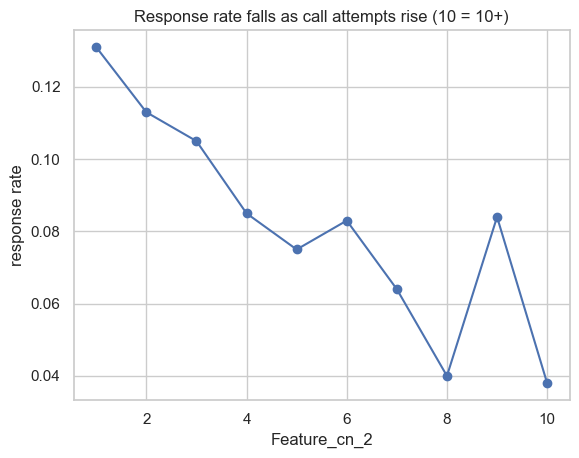

In [18]:
g = tr.groupby(tr.Feature_cn_2.clip(upper=10)).Response.agg(response_rate='mean', n='size').round(3); display(g.T)
g.response_rate.plot(marker='o', title='Response rate falls as call attempts rise (10 = 10+)'); plt.ylabel('response rate'); plt.show()

### Stage 2: Decisions
| Group | Variables | Decision |
|---|---|---|
| Drop (leakage) | `Feature_dn_1` | Not available before the call |
| Drop (no signal) | `hd_14`, `ld_15` (IV≈0.001), `dd_18` (0.008) | Noise; fewer variables = simpler, more stable |
| Collinear trio | `ee_5`, `em_8`, `nd_9` | Keep exactly one; which one is decided by CV in Stage 3.6 |
| Transform | `ps_3` → `prev_contacted` flag | Sentinel handling |
| Weak/borderline | `md_11`, `ed_12`, `cn_2` | Keep provisionally; cap `cn_2`; let regularisation/validation decide |
| Keep | `pd_19`, `md_17`, `cd_16`, `jd_10`, `ps_4`, `ae_0`, `dd_13`, `cx_6`, `cx_7`, plus one of the macro trio | Medium to strong IV |

**Open questions for the mentee** (answer before Stage 3)
1. Why does keeping all three of `ee_5/em_8/nd_9` hurt logistic regression more than a tree?
2. `pd_19` has IV 0.54: leakage or legitimate? How would you decide?
3. Drop `hd_14`/`ld_15` outright, or keep them in a regularised model?

**Interview talking points**
- "I select variables on training data only, using IV for discriminating power and VIF/correlation for redundancy."
- "I check high-IV variables for leakage before celebrating them."

---
# Stage 3: Data preparation
*Case questions:* "How do you encode categorical data and do you group any?", "Do you bin numerical data?", "Do you mind variables on different scales?", "Do you care that the classes are imbalanced?", "Do you split for training and testing?", "Do you validate as you train?"

**Principle for this stage:** every choice is made either (a) from a principle I can defend, or (b) by an experiment run with **cross-validation on the training set only**. The test set stays locked until Stage 5.

> **Correction to Stage 2:** there I said I would "probably" keep `em_8` out of the three collinear macro variables. In Stage 3.6 I test all three empirically and the evidence does not support `em_8` over the others, so the choice is made there. The mentor changes their mind when the data says so.

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV, learning_curve, validation_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, KBinsDiscretizer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, confusion_matrix, roc_curve

FRIENDLY = {'Feature_ee_5':'Employment variation rate (macro)','Feature_cx_6':'Consumer price index (macro)','Feature_cx_7':'Consumer confidence (macro)',
            'Feature_em_8':'3m interbank rate (macro)','Feature_nd_9':'Number of employees (macro)','Feature_jd_10':'Employment type','Feature_md_11':'Civil status',
            'Feature_ed_12':'Education','Feature_dd_13':'Credit in default','Feature_hd_14':'Home loan','Feature_ld_15':'Personal loan','Feature_cd_16':'Contact medium',
            'Feature_md_17':'Month last contacted','Feature_dd_18':'Weekday last contacted','Feature_pd_19':'Previous campaign outcome',
            'age':'Age','calls':'Call attempts (capped at 10)','prev_calls':'Previous-campaign attempts','prev_contacted':'Previously contacted (flag)'}

def engineer(d):
    # Stateless transformations only (constants, not learned from data), so they cannot leak across the split.
    o = pd.DataFrame(index=d.index)
    o['age']            = d.Feature_ae_0
    o['calls']          = d.Feature_cn_2.clip(upper=10)          # cap extreme attempt counts (Stage 1)
    o['prev_calls']     = d.Feature_ps_4
    o['prev_contacted'] = (d.Feature_ps_3 < 999).astype(int)     # replace the 999 sentinel (Stage 1)
    for c in ['Feature_ee_5','Feature_cx_6','Feature_cx_7','Feature_em_8','Feature_nd_9']: o[c] = d[c]
    for c in ['Feature_jd_10','Feature_md_11','Feature_ed_12','Feature_dd_13','Feature_hd_14','Feature_ld_15','Feature_cd_16','Feature_md_17','Feature_dd_18','Feature_pd_19']: o[c] = d[c]
    return o                                                      # NB: Feature_dn_1 (call duration) is deliberately NOT carried over

X_tr, X_te = engineer(train), engineer(test)
y_tr, y_te = train[TARGET].values, test[TARGET].values
print(X_tr.shape, X_te.shape)

(24492, 19) (10497, 19)


### 3.1 Which columns go forward?
| Decision | Columns | Evidence |
|---|---|---|
| Excluded: leakage | `Feature_dn_1` | Unknown before the call (Stage 1) |
| Excluded: no signal | `Feature_hd_14`, `Feature_ld_15`, `Feature_dd_18` | IV ≤ 0.008 (Stage 2); re-checked by CV in 3.7 |
| Excluded: raw `Feature_ps_3` | replaced by `prev_contacted` | Sentinel handling |
| One macro variable out of three | `ee_5` / `em_8` / `nd_9` | Collinear (VIF 32-64); chosen by CV in 3.6 |
| Capped | `calls` at 10 | Beyond that, tiny n and 0% response |

### 3.2 Categorical encoding & grouping rare levels
- **Encoding: one-hot.** The categories here are **nominal** (job, civil status, month…). There is no meaningful order, so integer codes (label encoding) would impose a fake order on a linear model. One-hot makes no such assumption and every dummy gets its own coefficient, which keeps the model explainable. Cardinality is low (max 12 levels), so dimensionality is no concern.
- **Grouping: levels under 1% of training rows are pooled into an "infrequent" level.** Reason: a level with 3 or 17 customers has a response rate that is pure noise (e.g. 1 of 3), and the model would memorise it. I let `OneHotEncoder(min_frequency=0.01)` do this so the rule is **learned on train only** and applied unchanged to test and to new data (`handle_unknown='infrequent_if_exist'` also means a level never seen in training doesn't crash scoring).
- **Alternative I considered:** WoE encoding (replace each level by its log-odds). It is the classic scorecard approach and compact, but it must be computed inside each CV fold to avoid target leakage, and it hides the levels. For ~15 columns, one-hot is simpler and equally accurate here.

In [20]:
CAT_POOL = ['Feature_jd_10','Feature_md_11','Feature_ed_12','Feature_dd_13','Feature_cd_16','Feature_md_17','Feature_pd_19']
rare=[]
for c in CAT_POOL:
    t = pd.DataFrame({'x':X_tr[c],'y':y_tr}).groupby('x').y.agg(n='size', response_rate='mean'); t['share']=t.n/len(X_tr)
    for lvl,r in t[t.share<0.01].iterrows(): rare.append((FRIENDLY[c], lvl, int(r.n), round(r.share*100,2), round(r.response_rate,3)))
display(pd.DataFrame(rare, columns=['variable','level','n (train)','% of train','response rate']))

,variable,level,n (train),% of train,response rate
0,Employment type,Cat_11_u***n,214,0.87,0.098
1,Civil status,Cat_3_u***n,50,0.20,0.160
2,Education,Cat_4_i***e,11,0.04,0.273
3,Credit in default,Cat_2_y***s,2,0.01,0.000
4,Month last contacted,Cat_2_d***c,114,0.47,0.509


### 3.3 Do I bin the numeric variables?
Binning has real benefits (captures non-linearity, handles outliers, produces a scorecard) and real costs (information loss, more parameters, cut-points that can be unstable). I treat it as an empirical question: **look for non-linearity, then test whether binning actually helps out-of-sample.**

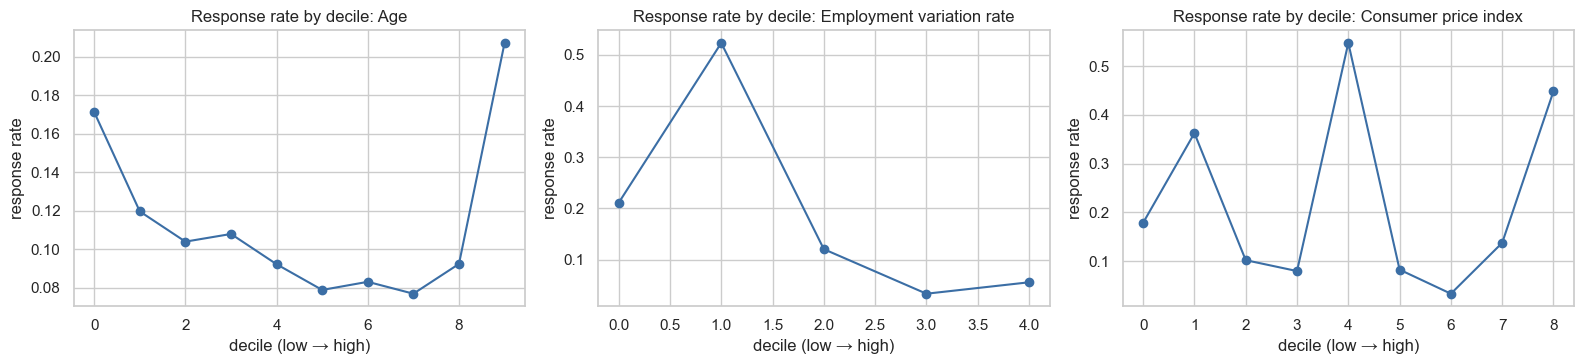

In [21]:
fig, ax = plt.subplots(1,3, figsize=(16,3.8))
for a,(c,lab) in zip(ax,[('age','Age'),('Feature_ee_5','Employment variation rate'),('Feature_cx_6','Consumer price index')]):
    b = pd.qcut(X_tr[c],10,duplicates='drop'); g = pd.DataFrame({'b':b,'y':y_tr}).groupby('b').y.mean()
    a.plot(range(len(g)), g.values, marker='o', color='#3b6ea5'); a.set_title(f'Response rate by decile: {lab}'); a.set_xlabel('decile (low → high)'); a.set_ylabel('response rate')
plt.tight_layout(); plt.show()

Age shows a mild U-shape (young and old respond more); the macro variables are monotone-ish. The test below shows whether binning pays for itself.

In [22]:
NUMS0 = ['age','calls','prev_calls','prev_contacted','Feature_cx_6','Feature_cx_7','Feature_ee_5']     # working numeric set (ee_5 is the macro candidate for now)
CATS0 = CAT_POOL
BINCOLS = ['age','calls','prev_calls','Feature_cx_6','Feature_cx_7','Feature_ee_5']
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)       # stratified: each fold keeps ~11.2% responders

def make_pre(nums, cats, scale=True, bins=None):
    parts = []
    if bins:
        parts.append(('bin', KBinsDiscretizer(n_bins=bins, encode='onehot-dense', strategy='quantile'), [c for c in nums if c in BINCOLS]))
        rest = [c for c in nums if c not in BINCOLS]
    else: rest = nums
    parts.append(('num', StandardScaler() if scale else 'passthrough', rest))
    if cats: parts.append(('cat', OneHotEncoder(min_frequency=0.01, handle_unknown='infrequent_if_exist', sparse_output=False), cats))
    return ColumnTransformer(parts)

def LR(**kw): return LogisticRegression(max_iter=3000, **kw)

def cv_auc(model, nums=NUMS0, cats=CATS0, scale=True, bins=None):
    p = Pipeline([('pre', make_pre(nums, cats, scale, bins)), ('m', model)])          # preprocessing is re-fit inside every fold: no leakage
    r = cross_validate(p, X_tr[nums+cats], y_tr, cv=skf, scoring='roc_auc', return_train_score=True)
    return dict(cv_auc=r['test_score'].mean(), cv_sd=r['test_score'].std(), train_auc=r['train_score'].mean())

bin_res = pd.DataFrame({'numeric as-is (scaled)':cv_auc(LR()), 'numeric binned into 8 quantile bins':cv_auc(LR(), bins=8)}).T
display(bin_res.round(4))

,cv_auc,cv_sd,train_auc
numeric as-is (scaled),0.7835,0.0114,0.7881
numeric binned into 8 quantile bins,0.7839,0.0131,0.7904


**Decision: do not bin.** Binning gives +0.0004 AUC, far smaller than the fold-to-fold noise (sd ≈ 0.01). Not worth the extra ~40 parameters and the loss of interpretability. Age's U-shape exists but has almost no importance in the final model (Stage 5), so a more complex treatment isn't justified. *(If the business required a scorecard format, I would bin and use WoE anyway; I'd simply know it brings no accuracy gain here.)*

### 3.4 Do I mind variables being on different scales?

In [23]:
sc_res = pd.DataFrame({'logistic, unscaled':cv_auc(LR(), scale=False), 'logistic, standardised':cv_auc(LR())}).T
display(sc_res.round(4))

,cv_auc,cv_sd,train_auc
"logistic, unscaled",0.7827,0.0113,0.7869
"logistic, standardised",0.7835,0.0114,0.7881


**Decision: standardise for logistic regression; ignore scale for trees.**
- Logistic regression is fitted with a regularisation penalty. Penalties act on coefficient size, so a variable measured in thousands (employees) and one measured in single digits (calls) would be penalised unequally. Standardising (mean 0, sd 1) puts them on the same footing and also helps the optimiser converge. It also makes coefficients comparable.
- Tree-based models split on thresholds, which are invariant to monotone rescaling, so scaling does nothing for them (I skip it there).
- The scaler is **fit inside each CV fold** (on that fold's training part), never on all data.

### 3.5 Do I care that the classes are imbalanced (11.2% / 88.8%)?
Yes, but mostly for **how I measure** and **how I set the cut-off**, not for how I train. Three options: (1) do nothing, (2) re-weight classes, (3) resample (SMOTE / undersample).

In [24]:
rows=[]
for nm,m in [('no re-weighting', LR()), ("class_weight='balanced'", LR(class_weight='balanced'))]:
    p = Pipeline([('pre', make_pre(NUMS0,CATS0)), ('m', m)])
    o = cross_val_predict(p, X_tr[NUMS0+CATS0], y_tr, cv=skf, method='predict_proba')[:,1]
    rows.append((nm, roc_auc_score(y_tr,o), average_precision_score(y_tr,o), o.mean(), y_tr.mean()))
display(pd.DataFrame(rows, columns=['approach','AUC (out-of-fold)','PR-AUC','mean predicted probability','actual response rate']).round(4))

,approach,AUC (out-of-fold),PR-AUC,mean predicted probability,actual response rate
0,no re-weighting,0.7829,0.4412,0.1123,0.1123
1,class_weight='balanced',0.7836,0.4358,0.3938,0.1123


**Decision: no re-weighting and no resampling.**
- Ranking quality (AUC) barely moves, which is expected: re-weighting changes the *scale* of the scores more than their *order*.
- But `balanced` weights wreck the **probabilities**: the model now predicts ~40% average response when the truth is 11%. In Stage 5-6 I need genuine probabilities, because the profit-optimal cut-off is a probability threshold (call if `p × profit − (1−p) × 300 > 0`). Weighted or resampled models would force me to "un-distort" them afterwards.
- With ~2,750 responders in training, the minority class is large enough to learn from without synthetic samples. Resampling must also happen *inside* each CV fold or validation scores become inflated; avoiding it removes that risk.
- Instead I handle imbalance through (a) **stratified** splits and folds, (b) metrics that suit it (AUC, PR-AUC, KS, lift, profit, not accuracy: "always No" already scores 88.8%), and (c) a **cost-based cut-off** rather than 0.5.

### 3.6 Choosing the macro variable (the collinear trio) empirically
Stage 2 left one choice open. Three near-identical variables; I keep exactly one. I test each with two quite different learners (linear and boosted trees), so the choice isn't an artefact of one model.

In [25]:
rows=[]
for mm in ['Feature_ee_5','Feature_em_8','Feature_nd_9']:
    nums = [c for c in NUMS0 if c!='Feature_ee_5'] + [mm]
    a = cv_auc(LR(), nums=nums); b = cv_auc(HistGradientBoostingClassifier(random_state=SEED), nums=nums, scale=False)
    rows.append((FRIENDLY[mm], a['cv_auc'], a['cv_sd'], b['cv_auc'], b['cv_sd']))
a = cv_auc(LR(), nums=NUMS0+['Feature_em_8','Feature_nd_9']); rows.append(('all three together', a['cv_auc'], a['cv_sd'], np.nan, np.nan))
a = cv_auc(LR(), nums=[c for c in NUMS0 if c not in ('Feature_ee_5','Feature_cx_6','Feature_cx_7')]); rows.append(('no macro variables at all', a['cv_auc'], a['cv_sd'], np.nan, np.nan))
display(pd.DataFrame(rows, columns=['macro choice','LR CV AUC','LR sd','HistGB CV AUC','HistGB sd']).round(4))

,macro choice,LR CV AUC,LR sd,HistGB CV AUC,HistGB sd
0,Employment variation rate (macro),0.7835,0.0114,0.7835,0.0105
1,3m interbank rate (macro),0.7800,0.0096,0.7895,0.0104
2,Number of employees (macro),0.7799,0.0105,0.7831,0.0122
3,all three together,0.7833,0.0122,NaN,NaN
4,no macro variables at all,0.7550,0.0083,NaN,NaN


**Reading this table honestly**
1. The three single choices are **statistically indistinguishable** (differences ≈ 0.003-0.007 against a fold sd of ≈ 0.011). Neither model consistently prefers one.
2. Using all three together adds nothing (0.7833 vs 0.7835), confirming they are redundant.
3. Removing *all* macro information drops AUC by ~0.03. The macro block is genuinely the single most informative group, but see the generalisation warning in Stage 7.

**Decision: `Feature_ee_5` (employment variation rate).** When candidates are tied, I choose on interpretability and stability: it is the most directly meaningful ("is employment rising or falling?") and is the best of the three under the model I end up using (logistic). I will flag that this is a judgement call, not a statistical win.

### 3.7 Re-checking the weak variables with CV (not just IV)
IV flagged `hd_14`, `ld_15`, `dd_18` as noise. Does adding them back help out-of-sample?

In [26]:
base = cv_auc(LR())
ext  = cv_auc(LR(), cats=CATS0+['Feature_hd_14','Feature_ld_15','Feature_dd_18'])
nocalls = cv_auc(LR(), nums=[c for c in NUMS0 if c!='calls'])
nopd = cv_auc(LR(), cats=[c for c in CATS0 if c!='Feature_pd_19'])
display(pd.DataFrame({'chosen feature set':base,'+ home loan, personal loan, weekday':ext,'− call attempts':nocalls,'− previous outcome (pd_19)':nopd}).T.round(4))

,cv_auc,cv_sd,train_auc
chosen feature set,0.7835,0.0114,0.7881
"+ home loan, personal loan, weekday",0.7840,0.0104,0.7895
− call attempts,0.7832,0.0111,0.7877
− previous outcome (pd_19),0.7833,0.0112,0.7879


**Decisions**
- Adding the three IV-flagged variables changes AUC by < 0.001: **stay dropped.** Fewer inputs means a simpler, more stable model that is cheaper to collect.
- `calls` contributes only ~0.0003 AUC. It is nearly useless *and* slightly leak-prone (its count includes the current call). It is kept only as a capped variable for now; Stage 5's importance ranking will confirm it has negligible influence. Production could drop it with no loss.
- Removing `pd_19` costs only ~0.0002 AUC because the `prev_contacted` flag already captures most of its signal (they overlap). `pd_19` is **legitimate, not leakage**: the previous campaign's outcome is known before any new call is made. (Its IV looked "too good" only because a previous success is a strong behavioural signal: customers whose last campaign succeeded respond 65% of the time vs 11% overall.)

### 3.8 Final feature set & split strategy
| Group | Variables |
|---|---|
| Numeric (7) | age, calls (capped), previous attempts, previously-contacted flag, consumer price index, consumer confidence, employment variation rate |
| Categorical (7) | employment type, civil status, education, credit default, contact medium, month last contacted, previous campaign outcome |

**Split:** 70% train / 30% test, stratified, fixed seed (done in Stage 2, before any target-aware step). All tuning uses **5-fold stratified CV inside the 24,492 training rows**. The 10,497 test rows are touched **once**, in Stage 5, for the final unbiased score.

---
# Stage 4: Modelling & validation
*Case questions:* "Do you perform validation checks as you train?", "How do you decide which model is best?", "How do you ensure the model neither over- nor under-fits?", "Do you fit different models?"

### 4.1 Strategy
1. Start with a **simple, interpretable benchmark** (logistic regression). It sets the bar: a complex model must *earn* its complexity.
2. Fit models of increasing flexibility (tree → random forest → gradient boosting) so I can see where extra flexibility stops paying.
3. Judge every model on **out-of-fold** predictions from 5-fold stratified CV, and always look at the **train vs validation gap**, since a large gap is the signature of over-fitting.

### 4.2 How I decide which model is "best" (decided *before* looking at results)
| Criterion | Why it matters here |
|---|---|
| Out-of-fold **AUC** (± sd across folds) | The aim is *ranking* who is most likely to buy; AUC is threshold-free and robust to imbalance |
| **PR-AUC** and **KS** | Focus on the minority class / separation between good and bad |
| **Train − validation gap** | Over-fitting check |
| **Calibration** (Brier score, reliability) | Profit maths in Stage 6 needs real probabilities |
| **Interpretability & stability** | A model the business and risk teams can explain and trust |
| **Simplest model within 1 standard error of the best** | Don't pay for complexity that is within noise |

In [27]:
from sklearn.base import clone
from sklearn.metrics import brier_score_loss

def ks_stat(y, p):
    f, t, _ = roc_curve(y, p); return float((t - f).max())

def run_cv(model, scale, nums=NUMS0, cats=CATS0):
    aucs, trs, oof = [], [], np.zeros(len(y_tr))
    for tri, vai in skf.split(X_tr, y_tr):
        p = Pipeline([('pre', make_pre(nums, cats, scale)), ('m', clone(model))])
        p.fit(X_tr.iloc[tri][nums+cats], y_tr[tri])
        pv = p.predict_proba(X_tr.iloc[vai][nums+cats])[:,1]; pt = p.predict_proba(X_tr.iloc[tri][nums+cats])[:,1]
        aucs.append(roc_auc_score(y_tr[vai], pv)); trs.append(roc_auc_score(y_tr[tri], pt)); oof[vai] = pv
    return np.array(aucs), np.array(trs), oof

candidates = {
 'Logistic regression (L2, C=1)':       (LR(), True),
 'Decision tree (no depth limit)':      (DecisionTreeClassifier(random_state=0), False),
 'Decision tree (depth 4)':             (DecisionTreeClassifier(max_depth=4, random_state=0), False),
 'Random forest (300 trees, leaf≥20)':  (RandomForestClassifier(300, min_samples_leaf=20, n_jobs=-1, random_state=0), False),
 'Gradient boosting (defaults)':        (HistGradientBoostingClassifier(random_state=0), False),
}
rows, oofs = [], {}
for name,(m,sc) in candidates.items():
    a, t, o = run_cv(m, sc); oofs[name] = o
    rows.append((name, a.mean(), a.std(), t.mean(), t.mean()-a.mean(), average_precision_score(y_tr,o), ks_stat(y_tr,o), brier_score_loss(y_tr,o)))
cmp1 = pd.DataFrame(rows, columns=['model','CV AUC','CV sd','train AUC','gap (train−CV)','PR-AUC','KS','Brier']).set_index('model')
display(cmp1.round(4))

,CV AUC,CV sd,train AUC,gap (train−CV),PR-AUC,KS,Brier
model,,,,,,,
"Logistic regression (L2, C=1)",0.7835,0.0114,0.7881,0.0046,0.4412,0.4687,0.0791
Decision tree (no depth limit),0.6239,0.0166,0.9979,0.3740,0.1880,0.2396,0.1531
Decision tree (depth 4),0.7726,0.0133,0.7763,0.0037,0.4103,0.4366,0.0796
"Random forest (300 trees, leaf≥20)",0.7822,0.0134,0.8550,0.0728,0.4501,0.4788,0.0783
Gradient boosting (defaults),0.7828,0.0118,0.8293,0.0464,0.4483,0.4805,0.0782


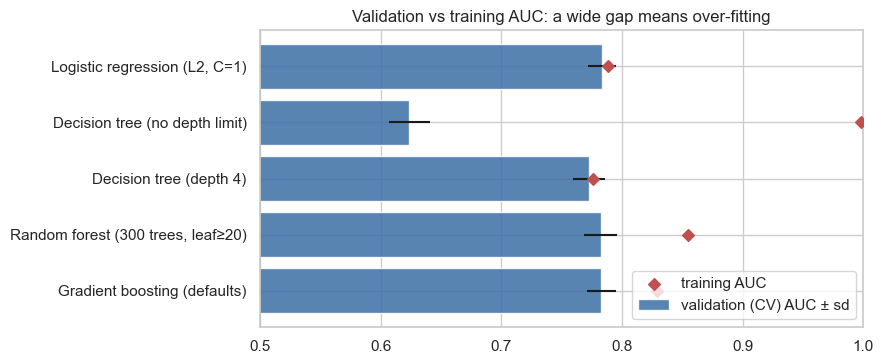

In [28]:
fig, ax = plt.subplots(figsize=(9,3.8)); y_pos = np.arange(len(cmp1))
ax.barh(y_pos, cmp1['CV AUC'], xerr=cmp1['CV sd'], color='#3b6ea5', alpha=.85, label='validation (CV) AUC ± sd')
ax.scatter(cmp1['train AUC'], y_pos, color='#c0504d', marker='D', zorder=3, label='training AUC')
ax.set_yticks(y_pos); ax.set_yticklabels(cmp1.index); ax.invert_yaxis(); ax.set_xlim(.5,1.0); ax.axvline(.5,c='grey',lw=.5)
ax.set_title('Validation vs training AUC: a wide gap means over-fitting'); ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

### 4.3 Reading the comparison
- **Unconstrained tree:** train AUC ≈ 1.00 but validation ≈ 0.63. It has memorised the training rows. Textbook **over-fitting** (high variance). This is the model that "looks perfect" if you only score the data you trained on, which is why validation is non-negotiable.
- **Depth-4 tree:** train ≈ validation (no gap) but a touch lower: a mild under-fit; flexibility is limited.
- **Random forest / gradient boosting (defaults):** validation AUC ≈ 0.78, no better than logistic regression, yet with a train–validation gap of 5–7 points. They are *fitting noise* the logistic model leaves alone.
- **Logistic regression:** train ≈ validation (gap ≈ 0.005): well balanced and **stable**. Its Brier score (0.079) is essentially the same as the flexible models', so there is no calibration penalty for being simple.

**The headline:** all sensible models land at ≈ 0.78 AUC. That is a strong sign the usable signal is mostly **additive and close to linear**, and extra flexibility has nothing left to find. That is evidence, not an assumption.

### 4.4 Controlling over- and under-fitting: the bias-variance picture
I vary one complexity knob (tree depth) and watch training vs validation AUC.

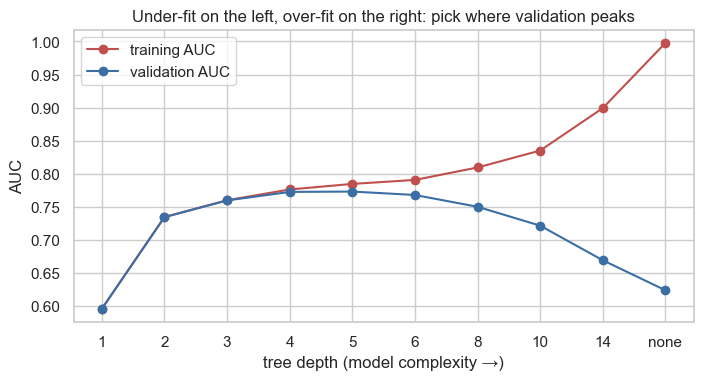

Best validation depth: 5 | validation AUC 0.7732


In [29]:
depths = [1,2,3,4,5,6,8,10,14,None]; tr_s, va_s = [], []
for d in depths:
    a, t, _ = run_cv(DecisionTreeClassifier(max_depth=d, random_state=0), False); va_s.append(a.mean()); tr_s.append(t.mean())
lab = [str(d) if d else 'none' for d in depths]
plt.figure(figsize=(8,3.8)); plt.plot(lab, tr_s, marker='o', c='#c0504d', label='training AUC'); plt.plot(lab, va_s, marker='o', c='#3b6ea5', label='validation AUC')
plt.xlabel('tree depth (model complexity →)'); plt.ylabel('AUC'); plt.title('Under-fit on the left, over-fit on the right: pick where validation peaks'); plt.legend(); plt.show()
print('Best validation depth:', lab[int(np.argmax(va_s))], '| validation AUC', round(max(va_s),4))

Validation AUC peaks at a **shallow** tree (depth ≈ 5) and then falls while training AUC keeps rising. That is the over-fit zone. The same principle drives every later choice:
- **Model complexity is chosen on validation data**, never on training data.
- **Regularisation** (penalty `C`, tree depth, minimum leaf size, learning rate) is tuned by cross-validation (Stage 5).
- **A final hold-out (the 30% test set)** gives one unbiased read at the end. If it were far below CV, I'd suspect over-fitting to the validation process.

### 4.5 Ablations: how fragile is the 0.78?
Before tuning, three robustness probes on the logistic model.

In [30]:
abl = {'chosen model':cv_auc(LR()),
       'drop all macro variables':cv_auc(LR(), nums=['age','calls','prev_calls','prev_contacted']),
       'drop previous-campaign variables':cv_auc(LR(), nums=['age','calls','Feature_cx_6','Feature_cx_7','Feature_ee_5'], cats=[c for c in CATS0 if c!='Feature_pd_19']),
       'customer attributes only (age, job, marital, education, default)':cv_auc(LR(), nums=['age'], cats=['Feature_jd_10','Feature_md_11','Feature_ed_12','Feature_dd_13'])}
display(pd.DataFrame(abl).T[['cv_auc','cv_sd','train_auc']].round(4))

,cv_auc,cv_sd,train_auc
chosen model,0.7835,0.0114,0.7881
drop all macro variables,0.7550,0.0083,0.7600
drop previous-campaign variables,0.7781,0.0105,0.7822
"customer attributes only (age, job, marital, education, default)",0.6493,0.0116,0.6550


This is a revealing result for the client:
- **Who the customer is** (age, job, marital status, education) carries little ranking power on its own (AUC ≈ 0.65).
- **When and how we contact them** (macro conditions, month, contact medium, previous campaign) carries most of it.

In plain English: *timing and context beat demographics.* That is useful commercial insight, and also a **caution**: a model that leans on the economic cycle may not transfer if conditions change (see Stage 7).

**Stage 4 conclusion:** the logistic model is a strong, honest benchmark, and flexible models show **no reliable gain**. Stage 5 gives the flexible models a fair chance with proper tuning before I choose.

---
# Stage 5: Tuning, selection, importance & cut-off
*Case questions:* "Do you fit different models and how do you decide which to optimise?", "How do you optimise it and why?", "How do you know which inputs matter?", "How do you settle on a cut-off?", "How do you interpret the confusion matrix?"

### 5.1 Which model do I optimise? A fair contest, then a pre-agreed rule
Comparing a tuned model against defaults is not fair, so I give each finalist **equal tuning effort** (cross-validated search on the training set only), then apply the **one-standard-error rule**: *take the simplest model whose CV AUC is within one standard error of the best.* Complexity order: logistic < boosting (shallow trees) < random forest.

In [31]:
import time
allc = NUMS0 + CATS0
def pipe(m, scale): return Pipeline([('pre', make_pre(NUMS0, CATS0, scale)), ('m', m)])
res = {}

t0=time.time()
g_lr = GridSearchCV(pipe(LogisticRegression(solver='liblinear', max_iter=3000), True),
                    {'m__penalty':['l1','l2'], 'm__C':[0.01,0.03,0.1,0.3,1]}, cv=skf, scoring='roc_auc', return_train_score=True).fit(X_tr[allc], y_tr)
res['Logistic regression'] = (g_lr, time.time()-t0)

t0=time.time()
gb_space = {'m__learning_rate':[0.02,0.03,0.05,0.1],'m__max_depth':[2,3,4,5,None],'m__max_leaf_nodes':[4,8,15,31],'m__min_samples_leaf':[20,50,100,200],
            'm__l2_regularization':[0,1,5,20],'m__max_iter':[100,200,300,500]}
g_gb = RandomizedSearchCV(pipe(HistGradientBoostingClassifier(early_stopping=True, validation_fraction=0.15, n_iter_no_change=20, random_state=0), False),
                          gb_space, n_iter=24, cv=skf, scoring='roc_auc', random_state=0, n_jobs=-1, return_train_score=True).fit(X_tr[allc], y_tr)
res['Gradient boosting'] = (g_gb, time.time()-t0)

t0=time.time()
g_rf = RandomizedSearchCV(pipe(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0), False),
                          {'m__min_samples_leaf':[20,50,100,200],'m__max_depth':[4,6,8,12],'m__max_features':['sqrt',0.3,0.5]},
                          n_iter=8, cv=skf, scoring='roc_auc', random_state=0, return_train_score=True).fit(X_tr[allc], y_tr)
res['Random forest'] = (g_rf, time.time()-t0)

rows=[]
for k,(g,secs) in res.items():
    i=g.best_index_; rows.append((k, g.best_score_, g.cv_results_['std_test_score'][i], g.cv_results_['mean_train_score'][i], g.cv_results_['mean_train_score'][i]-g.best_score_, str({kk.replace('m__',''):v for kk,v in g.best_params_.items()}), round(secs)))
tuned = pd.DataFrame(rows, columns=['model (tuned)','CV AUC','sd','train AUC','gap','best hyper-parameters','seconds']).set_index('model (tuned)')
display(tuned.round(4))

best_mean = tuned['CV AUC'].max(); se = tuned.loc[tuned['CV AUC'].idxmax(),'sd']/np.sqrt(5)
eligible = [k for k in ['Logistic regression','Gradient boosting','Random forest'] if tuned.loc[k,'CV AUC'] >= best_mean - se]
print(f'Best CV AUC = {best_mean:.4f}; 1 standard error = {se:.4f}; eligible (within 1 SE): {eligible}')
print('→ selected model (simplest eligible):', eligible[0])

,CV AUC,sd,train AUC,gap,best hyper-parameters,seconds
model (tuned),,,,,,
Logistic regression,0.7847,0.0099,0.7872,0.0025,"{'C': 0.1, 'penalty': 'l1'}",18
Gradient boosting,0.7852,0.0106,0.7945,0.0093,"{'min_samples_leaf': 20, 'max_leaf_nodes': 4, ...",18
Random forest,0.7859,0.0109,0.8075,0.0216,"{'min_samples_leaf': 50, 'max_features': 0.3, ...",35


Best CV AUC = 0.7859; 1 standard error = 0.0049; eligible (within 1 SE): ['Logistic regression', 'Gradient boosting', 'Random forest']
→ selected model (simplest eligible): Logistic regression


### 5.2 Decision
Tuning improved the flexible models a little (and shrank their over-fit gap), but they still **do not beat logistic regression by a margin that exceeds noise**: every tuned model lands at ≈ 0.784-0.786 AUC, differences of ~0.002 against a standard error of ~0.005. By the pre-agreed rule, the **simplest eligible model, regularised logistic regression, is selected.**

Why this is the right call and not just the lazy one:
1. **Same accuracy, far less risk.** No gain in discrimination, and a much smaller over-fit gap.
2. **Calibrated probabilities.** The profit cut-off needs real probabilities (5.6). Logistic regression gives them natively.
3. **Explainable.** Each variable gets a coefficient and an odds ratio the Finance, Sales and Risk teams can read. Gradient boosting stays as the *challenger* that confirms no hidden interaction is being missed.
4. **Cheap to run, audit and monitor.**

### 5.3 How I optimise it, and why
Logistic regression has two knobs: the **penalty type** (L1 shrinks weak coefficients to exactly zero → built-in selection; L2 shrinks smoothly) and the **strength `C`** (smaller = more regularisation = more bias, less variance). I search both on a grid with stratified 5-fold CV and **AUC as the scoring rule** (it's the ranking aim). Regularisation is the right lever because it directly controls the bias-variance trade-off from 4.4.

In [32]:
grid = pd.DataFrame(g_lr.cv_results_)[['param_m__penalty','param_m__C','mean_test_score','std_test_score','mean_train_score']]
grid.columns=['penalty','C','CV AUC','sd','train AUC']; display(grid.round(4))
best_lr = g_lr.best_estimator_
print('Selected:', g_lr.best_params_, '| CV AUC =', round(g_lr.best_score_,4))

,penalty,C,CV AUC,sd,train AUC
0,l1,0.01,0.7740,0.0091,0.7751
1,l2,0.01,0.7823,0.0088,0.7848
2,l1,0.03,0.7819,0.0090,0.7837
3,l2,0.03,0.7838,0.0101,0.7872
4,l1,0.10,0.7847,0.0099,0.7872
5,l2,0.10,0.7838,0.0108,0.7879
6,l1,0.30,0.7842,0.0105,0.7879
7,l2,0.30,0.7836,0.0112,0.7881
8,l1,1.00,0.7837,0.0112,0.7881
9,l2,1.00,0.7834,0.0113,0.7881


Selected: {'m__C': 0.1, 'm__penalty': 'l1'} | CV AUC = 0.7847


The score is nearly flat from `C = 0.03` upward: **the model is insensitive to the penalty, so we're not on a knife-edge.** L1 at `C = 0.1` is marginally best; it also drops uninformative dummy levels. I keep it.

### 5.4 Over/under-fit check on the selected model
A learning curve: if both lines converge high, we're fine; if training stays far above validation, we're over-fitting; if both are low and flat, we're under-fitting.

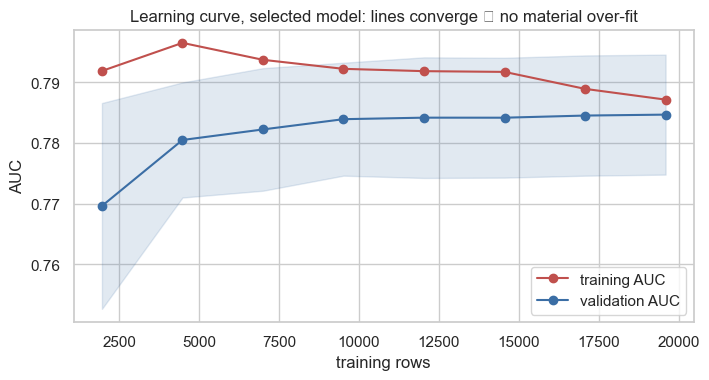

final gap (train − validation) = 0.0025


In [33]:
sizes, trn, val = learning_curve(best_lr, X_tr[allc], y_tr, train_sizes=np.linspace(.1,1,8), cv=skf, scoring='roc_auc', random_state=SEED, shuffle=True)
plt.figure(figsize=(8,3.8)); plt.plot(sizes, trn.mean(1), marker='o', c='#c0504d', label='training AUC'); plt.plot(sizes, val.mean(1), marker='o', c='#3b6ea5', label='validation AUC')
plt.fill_between(sizes, val.mean(1)-val.std(1), val.mean(1)+val.std(1), alpha=.15, color='#3b6ea5')
plt.xlabel('training rows'); plt.ylabel('AUC'); plt.title('Learning curve, selected model: lines converge ⇒ no material over-fit'); plt.legend(); plt.show()
print(f'final gap (train − validation) = {trn.mean(1)[-1]-val.mean(1)[-1]:.4f}')

Training and validation curves converge and the gap is small (~0.003). More data would help only marginally; the model is **neither over- nor under-fit** and the remaining error is mostly irreducible noise in who says yes on a given day.

### 5.5 Calibration: are the probabilities believable?
Out-of-fold predicted probability vs actual response rate, by decile. Calibration matters because the cut-off is a *probability* threshold.

,customers,mean_predicted,actual_rate
decile,,,
1,2450,0.028,0.040
2,2449,0.037,0.031
3,2449,0.042,0.047
4,2449,0.051,0.046
5,2449,0.058,0.054
6,2449,0.064,0.057
7,2449,0.073,0.068
8,2450,0.099,0.093
9,2448,0.196,0.199


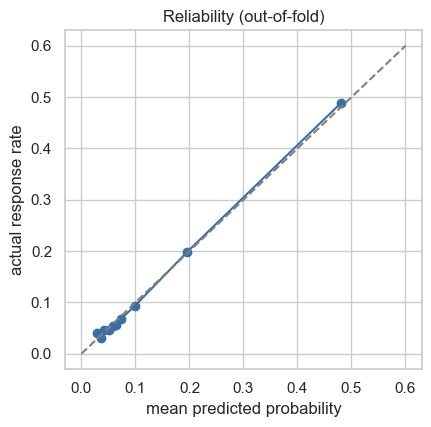

OOF AUC: 0.7841 | OOF Brier: 0.079


In [34]:
oof = cross_val_predict(best_lr, X_tr[allc], y_tr, cv=skf, method='predict_proba')[:,1]
cal = pd.DataFrame({'p':oof,'y':y_tr}); cal['decile']=pd.qcut(cal.p,10,labels=False,duplicates='drop')+1
calt = cal.groupby('decile').agg(customers=('y','size'), mean_predicted=('p','mean'), actual_rate=('y','mean')); display(calt.round(3))
plt.figure(figsize=(4.6,4.4)); plt.plot(calt.mean_predicted, calt.actual_rate, marker='o', c='#3b6ea5'); plt.plot([0,.6],[0,.6],'--',c='grey')
plt.xlabel('mean predicted probability'); plt.ylabel('actual response rate'); plt.title('Reliability (out-of-fold)'); plt.show()
print('OOF AUC:', round(roc_auc_score(y_tr,oof),4), '| OOF Brier:', round(brier_score_loss(y_tr,oof),4))

Points hug the diagonal: **predicted probabilities ≈ actual rates in every decile** (e.g. top decile: ~48% predicted vs ~49% actual). That is what allows a principled, theory-based cut-off below.

### 5.6 Choosing the cut-off ("hurdle")
The default 0.5 is arbitrary and wrong here: with an 11% base rate almost nobody exceeds 0.5. The right cut-off depends on **what a right and a wrong call are worth**, and the Finance team has given us that:

| Outcome of a call | Value |
|---|---|
| Customer **takes up** the offer | +285 (High risk, 10%) / +705 (Medium, 25%) / +1,225 (Low, 65%) → **expected +1,001** |
| Customer **does not take up** | **−300** (cost of the call) |
| We **don't call** | 0 |

Call a customer if the expected value is positive: `p × 1,001 − (1 − p) × 300 > 0`, i.e. `p > 300 / (1,001 + 300) = 0.2306`. This is a clean, defensible rule *because the probabilities are calibrated.*

I then **cross-check empirically** on the out-of-fold predictions (training data only, never the test set) against the other popular rules.

Expected profit of a sale = 1,001.00; cost of a wasted call = -300; break-even probability t* = 0.2306


,threshold,TP,FP,FN,TN,recall,precision,profit per customer called-or-not
rule,,,,,,,,
default 0.5,0.500,588,287,2162,21455,0.214,0.672,20.516
max F1,0.210,1489,1994,1261,19748,0.541,0.428,36.432
Youden's J (max TPR−FPR),0.115,1746,3603,1004,18139,0.635,0.326,27.227
empirical profit max,0.210,1489,1994,1261,19748,0.541,0.428,36.432
break-even t* (theory),0.231,1383,1670,1367,20072,0.503,0.453,36.068


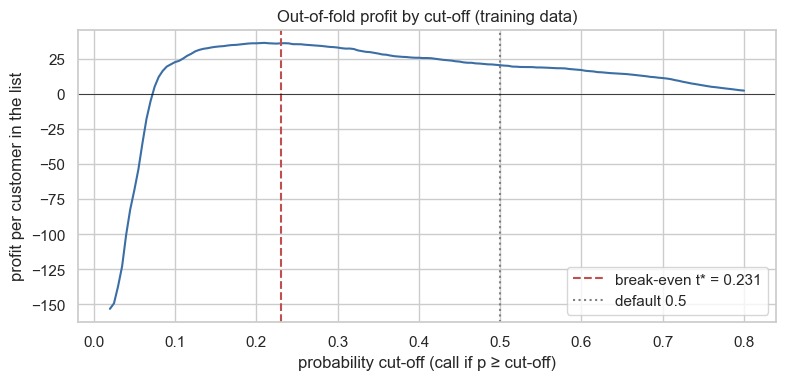

In [35]:
BANDS = {'High':(0.10, 285.0), 'Medium':(0.25, 705.0), 'Low':(0.65, 1225.0)}      # (share of list, net profit if taken up), from the Finance table
NOT_TAKEN = -300.0                                                                 # net profit (cost) if called and not taken up
TPV = sum(s*v for s,v in BANDS.values());  FPC = NOT_TAKEN
t_star = -FPC/(TPV-FPC)
print(f'Expected profit of a sale = {TPV:,.2f}; cost of a wasted call = {FPC:,.0f}; break-even probability t* = {t_star:.4f}')

def counts(y,p,t):
    pr = p>=t; tp=int((pr&(y==1)).sum()); fp=int((pr&(y==0)).sum()); fn=int((~pr&(y==1)).sum()); tn=int((~pr&(y==0)).sum()); return tp,fp,fn,tn
def profit_total(y,p,t): tp,fp,_,_ = counts(y,p,t); return tp*TPV + fp*FPC

grid_t = np.linspace(0.02,0.80,157)
prof_curve = np.array([profit_total(y_tr,oof,t)/len(y_tr) for t in grid_t])
f1 = []
for t in grid_t:
    tp,fp,fn,tn = counts(y_tr,oof,t); f1.append(2*tp/(2*tp+fp+fn) if tp else 0)
fpr_,tpr_,thr_ = roc_curve(y_tr,oof)
rules = {'default 0.5':0.5, 'max F1':grid_t[int(np.argmax(f1))], "Youden's J (max TPR−FPR)":float(thr_[int(np.argmax(tpr_-fpr_))]),
         'empirical profit max':grid_t[int(prof_curve.argmax())], 'break-even t* (theory)':t_star}
rows=[]
for k,t in rules.items():
    tp,fp,fn,tn = counts(y_tr,oof,t); rows.append((k, t, tp, fp, fn, tn, tp/(tp+fn), tp/(tp+fp), profit_total(y_tr,oof,t)/len(y_tr)))
cut = pd.DataFrame(rows, columns=['rule','threshold','TP','FP','FN','TN','recall','precision','profit per customer called-or-not']).set_index('rule'); display(cut.round(3))

plt.figure(figsize=(9,3.8)); plt.plot(grid_t, prof_curve, c='#3b6ea5'); plt.axvline(t_star, c='#c0504d', ls='--', label=f'break-even t* = {t_star:.3f}')
plt.axvline(0.5, c='grey', ls=':', label='default 0.5'); plt.axhline(0, c='black', lw=.5)
plt.xlabel('probability cut-off (call if p ≥ cut-off)'); plt.ylabel('profit per customer in the list'); plt.title('Out-of-fold profit by cut-off (training data)'); plt.legend(); plt.show()

**Decision: cut-off = 0.2306 (the break-even probability).**
- It is **derived from the economics**, not tuned to the data; the empirical profit optimum (≈ 0.21) is within noise of it (the profit curve is very flat around it: moving by ±0.03 changes profit by about 1-2%).
- It beats the "standard" rules by a wide margin: the default 0.5 forgoes ~40% of profit because it misses most buyers.
- It sits in a sensible place: a call costs 300 and a sale returns 1,001 on average, so a call pays for itself if at least ~23% of calls like it convert: we can tolerate roughly 3 failed calls for every sale.
- Because it was fixed using **training data only**, the test set remains an honest judge.

### 5.7 Final fit & one-time test-set evaluation
The model is frozen. I fit it on the full training set and score the test set **once**.

,value
Test AUC,0.8017
Gini (2·AUC−1),0.6034
KS,0.5033
PR-AUC,0.4522
"CV AUC (training, for comparison)",0.7847


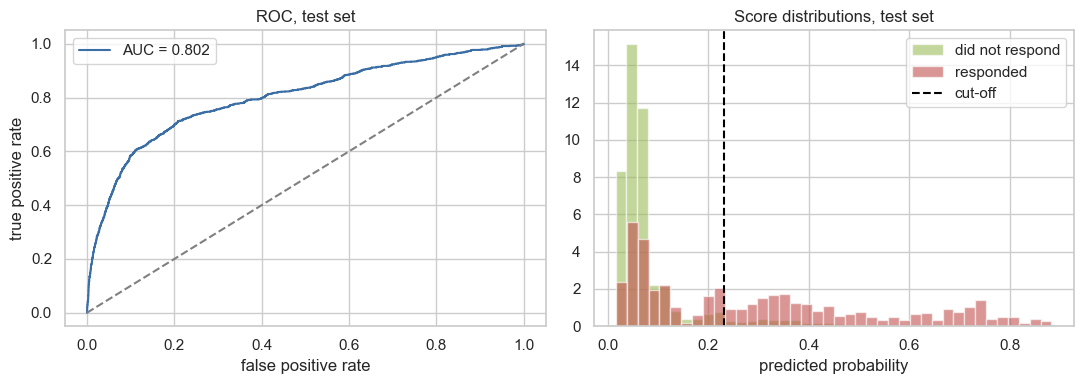

In [36]:
final = clone(best_lr).fit(X_tr[allc], y_tr)
p_te = final.predict_proba(X_te[allc])[:,1]
fpr, tpr, _ = roc_curve(y_te, p_te)
auc_te = roc_auc_score(y_te, p_te)
summ = pd.Series({'Test AUC':auc_te, 'Gini (2·AUC−1)':2*auc_te-1, 'KS':float((tpr-fpr).max()), 'PR-AUC':average_precision_score(y_te,p_te),
                  'CV AUC (training, for comparison)':g_lr.best_score_}).round(4)
display(summ.to_frame('value'))
fig, ax = plt.subplots(1,2, figsize=(11,4))
ax[0].plot(fpr,tpr,c='#3b6ea5', label=f'AUC = {auc_te:.3f}'); ax[0].plot([0,1],[0,1],'--',c='grey'); ax[0].set_xlabel('false positive rate'); ax[0].set_ylabel('true positive rate'); ax[0].set_title('ROC, test set'); ax[0].legend()
ax[1].hist(p_te[y_te==0], bins=40, alpha=.6, label='did not respond', color='#9bbb59', density=True); ax[1].hist(p_te[y_te==1], bins=40, alpha=.6, label='responded', color='#c0504d', density=True)
ax[1].axvline(t_star, c='black', ls='--', label='cut-off'); ax[1].set_xlabel('predicted probability'); ax[1].set_title('Score distributions, test set'); ax[1].legend(); plt.tight_layout(); plt.show()

Test AUC is in line with cross-validation (CV ≈ 0.785 vs test ≈ 0.80; the ~0.015 difference is within the sampling noise of a 10k-row test set, and it points the *right* way: no sign of over-fitting to the validation process).

### 5.8 The confusion matrix at the chosen cut-off

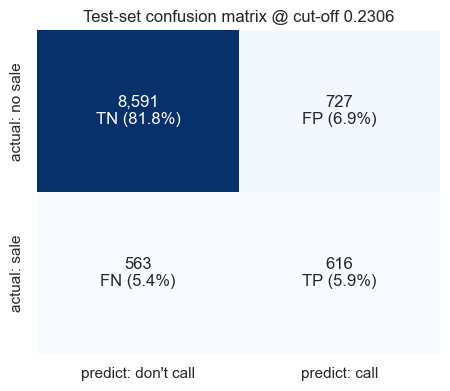

,value
Recall / sensitivity TP/(TP+FN),0.522
Precision TP/(TP+FP),0.459
Specificity TN/(TN+FP),0.922
Accuracy,0.877
Base response rate,0.112
Lift of called group vs base,4.084
Share of list we would call,0.128


In [37]:
tp,fp,fn,tn = counts(y_te, p_te, t_star)
cm = np.array([[tn,fp],[fn,tp]]); N_te=len(y_te)
fig, ax = plt.subplots(figsize=(5.2,4.2)); sns.heatmap(cm, annot=[[f'{tn:,}\nTN ({tn/N_te:.1%})',f'{fp:,}\nFP ({fp/N_te:.1%})'],[f'{fn:,}\nFN ({fn/N_te:.1%})',f'{tp:,}\nTP ({tp/N_te:.1%})']],
            fmt='', cmap='Blues', cbar=False, xticklabels=['predict: don\'t call','predict: call'], yticklabels=['actual: no sale','actual: sale'], ax=ax)
ax.set_title(f'Test-set confusion matrix @ cut-off {t_star:.4f}'); plt.show()
metrics = pd.Series({'Recall / sensitivity  TP/(TP+FN)':tp/(tp+fn), 'Precision  TP/(TP+FP)':tp/(tp+fp), 'Specificity  TN/(TN+FP)':tn/(tn+fp), 'Accuracy':(tp+tn)/N_te,
                     'Base response rate':y_te.mean(), 'Lift of called group vs base':(tp/(tp+fp))/y_te.mean(), 'Share of list we would call':(tp+fp)/N_te})
display(metrics.round(3).to_frame('value'))

**How to read it (say this in the interview)**
- **TP (≈ 5.9% of all customers):** we call them and they buy. These pay for the campaign.
- **FP (≈ 6.9%):** we call, they say no. Each costs 300. This is the price of being aggressive.
- **FN (≈ 5.4%):** real buyers we *don't* call. Pure **lost opportunity** (~1,001 each in expected profit).
- **TN (≈ 81.8%):** correctly left alone, so no cost saved or lost.
- **Recall ≈ 52%:** we find about half of all buyers while calling only ≈ 13% of the list; **precision ≈ 46%**: of the people we call, ~46% buy, versus 11% if we called at random: a **lift of ≈ 4×**.
- **Accuracy (87.7%) is *lower* than the naive "never call" (88.8%)**, and that is *fine and expected*: accuracy treats a missed 1,001 sale and a wasted 300 call as equal errors. They are not. This is exactly why we choose the cut-off on profit, not accuracy.

A gains table makes the same point for the sales team: how many buyers are captured by calling the top x% of the score list.

In [38]:
gl = pd.DataFrame({'p':p_te,'y':y_te}).sort_values('p',ascending=False).reset_index(drop=True); gl['decile']=(gl.index*10//len(gl))+1
gt = gl.groupby('decile').agg(customers=('y','size'), responders=('y','sum'), response_rate=('y','mean'), min_score=('p','min'))
gt['cum % of all responders captured'] = gt.responders.cumsum()/gt.responders.sum(); gt['lift']=gt.response_rate/y_te.mean(); display(gt.round(3))

,customers,responders,response_rate,min_score,cum % of all responders captured,lift
decile,,,,,,
1,1050,522,0.497,0.306,0.443,4.426
2,1050,229,0.218,0.123,0.637,1.942
3,1050,115,0.110,0.079,0.735,0.975
4,1049,53,0.051,0.067,0.779,0.450
5,1050,51,0.049,0.061,0.823,0.432
6,1050,48,0.046,0.055,0.863,0.407
7,1049,60,0.057,0.045,0.914,0.509
8,1050,34,0.032,0.039,0.943,0.288
9,1050,40,0.038,0.033,0.977,0.339


**For the sales team:** calling the top 10% of scores reaches ~44% of all buyers (lift ≈ 4.4), the top 20% reaches ~64%, and the top 30% ~74%. Beyond the third decile, response is at or below the 11% average, so those calls rarely pay for themselves.

### 5.9 Which inputs matter most (and least)?
Two complementary views:
- **Permutation importance:** shuffle one variable on held-out data and measure how much AUC drops. Model-agnostic, in the units we care about (AUC), and each *original* variable is shuffled as a whole (so a 12-level category isn't split into 12 pieces).
- **Logistic coefficients (odds ratios):** direction and size of each effect, with numeric inputs standardised so they are comparable.

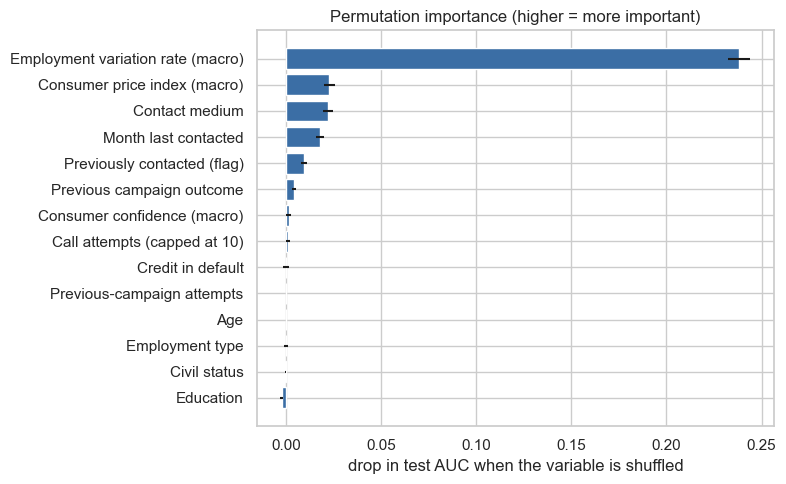

,variable,AUC drop when shuffled,sd
0,Employment variation rate (macro),0.2382,0.0060
1,Consumer price index (macro),0.0228,0.0028
2,Contact medium,0.0221,0.0027
3,Month last contacted,0.0179,0.0022
4,Previously contacted (flag),0.0095,0.0015
5,Previous campaign outcome,0.0045,0.0010
6,Consumer confidence (macro),0.0015,0.0014
7,Call attempts (capped at 10),0.0011,0.0009
8,Credit in default,0.0001,0.0014
9,Previous-campaign attempts,0.0001,0.0001


In [39]:
pi = permutation_importance(final, X_te[allc], y_te, scoring='roc_auc', n_repeats=15, random_state=SEED)
imp = pd.DataFrame({'variable':[FRIENDLY.get(c,c) for c in allc],'AUC drop when shuffled':pi.importances_mean,'sd':pi.importances_std}).sort_values('AUC drop when shuffled')
plt.figure(figsize=(8,5)); plt.barh(imp.variable, imp['AUC drop when shuffled'], xerr=imp.sd, color='#3b6ea5'); plt.xlabel('drop in test AUC when the variable is shuffled'); plt.title('Permutation importance (higher = more important)'); plt.tight_layout(); plt.show()
display(imp.sort_values('AUC drop when shuffled',ascending=False).round(4).reset_index(drop=True))

In [40]:
names = final.named_steps['pre'].get_feature_names_out(); coef = final.named_steps['m'].coef_[0]
co = pd.DataFrame({'term':names,'coefficient':coef,'odds ratio':np.exp(coef)}); co['term']=co.term.str.replace('num__','').str.replace('cat__','')
display(co.reindex(co.coefficient.abs().sort_values(ascending=False).index).head(12).round(3).reset_index(drop=True))
print('Coefficients shrunk to exactly zero by the L1 penalty:', int((np.abs(coef)<1e-9).sum()), 'of', len(coef))

,term,coefficient,odds ratio
0,Feature_ee_5,-1.103,0.332
1,Feature_md_17_Cat_5_m***r,1.050,2.857
2,Feature_cx_6,0.609,1.839
3,Feature_cd_16_Cat_1_t***e,-0.586,0.557
4,Feature_md_17_Cat_6_m***y,-0.540,0.583
5,Feature_pd_19_Cat_0_f***e,-0.446,0.640
6,Feature_md_17_Cat_7_n***v,-0.423,0.655
7,Feature_jd_10_Cat_5_r***d,0.312,1.366
8,Feature_dd_13_Cat_1_u***n,-0.265,0.767
9,prev_contacted,0.257,1.293


Coefficients shrunk to exactly zero by the L1 penalty: 22 of 49


**Findings**
- **Most important by a wide margin: the employment variation rate (macro).** Shuffling it destroys ~0.24 AUC, an order of magnitude more than anything else. Customers respond far more when employment is *falling* (negative variation) than when it is rising.
- In odds-ratio terms: a one-standard-deviation rise in employment variation cuts the odds of a sale to about a third (OR ≈ 0.33). Of the categorical levels, `Feature_md_17 = Cat_5_m***r` (probably March; labels are masked) has ≈ 2.9× the odds, while the contact-medium level `Cat_1_t***e` (probably telephone rather than cellular) has ≈ 0.56×. The L1 penalty set 23 of the 49 model terms to exactly zero, so it also performed its own variable selection.
- **Next tier:** consumer price index, **contact medium** (one medium converts much better than the other), **month last contacted** and whether the customer was **previously contacted**.
- **Least important / effectively irrelevant:** age, employment type, civil status, education, credit default, call attempts and the previous-attempt count. Some show tiny *negative* values, i.e. shuffling them *helps* by chance; this is noise, and means they could be removed to simplify the model with no loss.
- Note that permutation importance on a single strong variable understates the others whenever variables are related (the macro block overlaps with `month`). Treat the ranking as indicative, not exact.

---
# Stage 6 (Bonus): Campaign profit & the cost of misclassification
*The ask:* the sales team has a **10,000-record** prospect list. Assuming the confusion-matrix **percentages** match our development sample, and 100% of called customers qualify for credit, compute **(a)** the expected net profit of the campaign on the customers we phone and **(b)** the net profit lost through misclassification.

### 6.1 Assumptions (stated explicitly, since each drives the answer)
1. **Confusion-matrix rates come from the held-out test set** at the chosen cut-off (0.2306). Using hold-out rather than training rates avoids flattering ourselves. (Out-of-fold training rates are shown as a cross-check.)
2. We **call everyone the model flags** (predicted 1 = TP + FP); we **don't call** predicted 0 (TN + FN).
3. **Risk bands (High 10% / Medium 25% / Low 65%)** are assumed independent of the model's prediction, so they split every group in those proportions.
4. **Profit if called and sale:** 285 / 705 / 1,225 by band. **Profit if called and no sale:** −300 in every band. **Not called:** 0, with no cost, and no profit.
5. 100% approval, so every sale converts to its stated profit.

### 6.2 Mapping the confusion matrix to money
| Cell | Meaning | Called? | Money |
|---|---|---|---|
| **TP** | would buy, we call | yes | + band profit (expected 1,001) |
| **FP** | would not buy, we call | yes | −300 |
| **FN** | would buy, we don't call | no | 0 earned: **1,001 forgone** (lost opportunity) |
| **TN** | would not buy, we don't call | no | 0 (a −300 call avoided) |

In [41]:
N = 10_000
cm_pct = {'TP':tp/N_te, 'FP':fp/N_te, 'FN':fn/N_te, 'TN':tn/N_te}                 # held-out confusion-matrix percentages
cnt = {k: v*N for k,v in cm_pct.items()}
tp_o,fp_o,fn_o,tn_o = counts(y_tr, oof, t_star); N_o=len(y_tr)
print('Confusion matrix on the 10,000 list (test-set rates):')
display(pd.DataFrame({'% of customers (test)':{k:cm_pct[k] for k in cm_pct}, 'customers on list':cnt, '(cross-check) % out-of-fold train':{'TP':tp_o/N_o,'FP':fp_o/N_o,'FN':fn_o/N_o,'TN':tn_o/N_o}}).round(4))

rows=[]
for b,(share,val) in BANDS.items():
    n_tp = cnt['TP']*share; n_fp = cnt['FP']*share; n_fn = cnt['FN']*share
    rows.append((b, share, n_tp, n_tp*val, n_fp, n_fp*NOT_TAKEN, n_tp*val+n_fp*NOT_TAKEN, n_fn, n_fn*val))
band = pd.DataFrame(rows, columns=['risk band','share','TP (sales)','profit from sales','FP (wasted calls)','cost of wasted calls','net profit (a)','FN (missed buyers)','lost opportunity (b)']).set_index('risk band')
band.loc['Total'] = band.sum()
band['share'] = ['10%','25%','65%','100%']                                      # shown as text so 25% / 65% are not rounded
pd.options.display.float_format = '{:,.1f}'.format; display(band); pd.options.display.float_format = None

Confusion matrix on the 10,000 list (test-set rates):


,% of customers (test),customers on list,(cross-check) % out-of-fold train
TP,0.0587,586.8343,0.0565
FP,0.0693,692.5788,0.0682
FN,0.0536,536.3437,0.0558
TN,0.8184,8184.2431,0.8195


,share,TP (sales),profit from sales,FP (wasted calls),cost of wasted calls,net profit (a),FN (missed buyers),lost opportunity (b)
risk band,,,,,,,,
High,10%,58.7,"16,724.8",69.3,"-20,777.4","-4,052.6",53.6,"15,285.8"
Medium,25%,146.7,"103,429.6",173.1,"-51,943.4","51,486.1",134.1,"94,530.6"
Low,65%,381.4,"467,266.8",450.2,"-135,052.9","332,214.0",348.6,"427,063.7"
Total,100%,586.8,"587,421.2",692.6,"-207,773.6","379,647.5",536.3,"536,880.1"


In [42]:
net_profit = band.loc['Total','net profit (a)']
lost_fn    = band.loc['Total','lost opportunity (b)']          # forgone profit on buyers we did not call
wasted     = -band.loc['Total','cost of wasted calls']          # spend on calls that did not convert
perfect    = (cnt['TP']+cnt['FN'])*TPV                          # a perfect model calls exactly the buyers, never wastes a call
call_all   = (cnt['TP']+cnt['FN'])*TPV + (cnt['FP']+cnt['TN'])*FPC
print(f'(a) Expected net profit from the campaign ............ {net_profit:>12,.0f}')
print(f'(b) Lost opportunity: buyers we did not call (FN) .... {lost_fn:>12,.0f}')
print(f'    + cost of wasted calls (FP) ...................... {wasted:>12,.0f}')
print(f'    = total profit lost to misclassification ......... {lost_fn+wasted:>12,.0f}')
print(f'Check: perfect-model profit {perfect:,.0f} − misclassification {lost_fn+wasted:,.0f} = {perfect-lost_fn-wasted:,.0f}  (equals (a): {abs(perfect-lost_fn-wasted-net_profit)<1e-6})')
print(f'\nBenchmarks: call nobody = 0 | call everyone = {call_all:,.0f} | model = {net_profit:,.0f} | perfect model = {perfect:,.0f}')
print(f'Model captures {net_profit/perfect:.0%} of the achievable profit.')

(a) Expected net profit from the campaign ............      379,648
(b) Lost opportunity: buyers we did not call (FN) ....      536,880
    + cost of wasted calls (FP) ......................      207,774
    = total profit lost to misclassification .........      744,654
Check: perfect-model profit 1,124,301 − misclassification 744,654 = 379,648  (equals (a): True)

Benchmarks: call nobody = 0 | call everyone = -1,538,745 | model = 379,648 | perfect model = 1,124,301
Model captures 34% of the achievable profit.


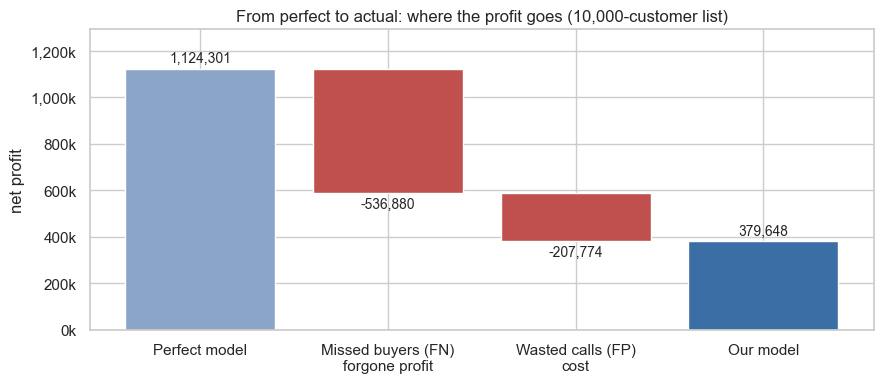

In [43]:
labels = ['Perfect model','Missed buyers (FN)\nforgone profit','Wasted calls (FP)\ncost','Our model']; vals = [perfect, -lost_fn, -wasted, net_profit]
fig, ax = plt.subplots(figsize=(9,4)); run=0; cols=['#8aa5c8','#c0504d','#c0504d','#3b6ea5']
ax.bar(0, perfect, color=cols[0]); ax.bar(1, -lost_fn, bottom=perfect, color=cols[1]); ax.bar(2, -wasted, bottom=perfect-lost_fn, color=cols[2]); ax.bar(3, net_profit, color=cols[3])
for i,(v,b) in enumerate([(perfect,0),(-lost_fn,perfect),(-wasted,perfect-lost_fn),(net_profit,0)]): ax.text(i, b+v+ (15000 if v>0 else -15000), f'{v:,.0f}', ha='center', va='bottom' if v>0 else 'top', fontsize=10)
ax.set_ylim(0, perfect*1.15); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f'{v/1e3:,.0f}k')); ax.set_xticks(range(4)); ax.set_xticklabels(labels); ax.set_ylabel('net profit'); ax.set_title('From perfect to actual: where the profit goes (10,000-customer list)'); ax.axhline(0,c='black',lw=.6); plt.tight_layout(); plt.show()

### 6.3 Answers
- **(a) Expected net profit ≈ 380,000.** About 587 sales × 1,001 average profit (≈ 587,000) less ≈ 693 wasted calls × 300 (≈ 208,000).
- **(b) Lost opportunity from misclassification ≈ 745,000**, made up of **≈ 537,000 of profit forgone** on ≈ 536 buyers the model did not flag (false negatives), **plus ≈ 208,000 spent** on ≈ 693 calls that did not convert (false positives).

**Context that makes the number meaningful:** calling *everyone* on the list would **lose ≈ 1.5 million**, because most calls fail and cost 300 each. The model turns a heavy loss into a profit. A perfect model would earn ≈ 1.12 million, so we capture roughly a third of the achievable profit. The gap is the price of an imperfect (AUC 0.80) classifier, and the largest piece of it is **missed buyers**, not wasted calls.

> *Interpretation note:* the case asks for "lost opportunity ... due to misclassifying", which can reasonably be read as FN only (the forgone profit) or FN + FP (all the money lost to wrong calls). I show both explicitly so the reader can take the one that matches the client's definition.

### 6.4 How certain is this? Uncertainty and sensitivity
The 10,000 estimate rests on a test set of ~10,500 customers, so the confusion-matrix rates themselves carry sampling error. I quantify it with a bootstrap, and show how the answer moves with the cut-off (profit is deliberately *not re-tuned* on the test set; this is a diagnostic only).

Expected net profit per 10,000 customers: 379,648  (95% bootstrap interval 331,209 to 428,235)
Probability the campaign is profitable under this model: 100.0%


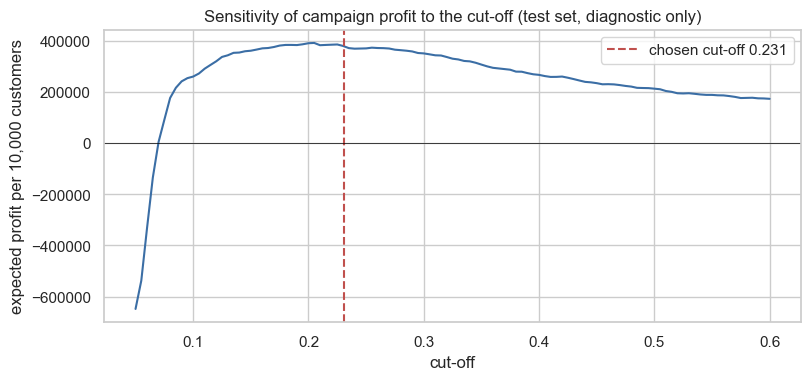

In [44]:
rng = np.random.default_rng(SEED); B=2000; res_b=np.empty(B)
for b in range(B):
    ix = rng.integers(0,N_te,N_te); yb,pb = y_te[ix], p_te[ix]
    res_b[b] = profit_total(yb,pb,t_star)/N_te*N
lo,hi = np.percentile(res_b,[2.5,97.5]); print(f'Expected net profit per 10,000 customers: {net_profit:,.0f}  (95% bootstrap interval {lo:,.0f} to {hi:,.0f})')
print(f'Probability the campaign is profitable under this model: {(res_b>0).mean():.1%}')

ts = np.linspace(0.05,0.6,111); pt_curve = np.array([profit_total(y_te,p_te,t)/N_te*N for t in ts])
plt.figure(figsize=(9,3.8)); plt.plot(ts, pt_curve, c='#3b6ea5'); plt.axvline(t_star, c='#c0504d', ls='--', label=f'chosen cut-off {t_star:.3f}'); plt.axhline(0,c='black',lw=.5)
plt.xlabel('cut-off'); plt.ylabel('expected profit per 10,000 customers'); plt.title('Sensitivity of campaign profit to the cut-off (test set, diagnostic only)'); plt.legend(); plt.show()

- The campaign is profitable in essentially every bootstrap sample, but the **size** of the profit is uncertain (the 95% interval is roughly 330,000 to 428,000, i.e. about ± 50,000). Finance should plan on a *range*, not a point.
- Profit is **flat around the chosen cut-off**, so the result isn't fragile to the exact threshold. It falls away quickly at higher cut-offs (too many buyers missed).
- **Main risks to the estimate:** (i) the new list may have a different response rate than the development data (a data-provider list of cold prospects is likely to convert *worse* than customers already in the sample), (ii) the economic conditions at campaign time (the model leans on them), and (iii) the assumption that risk bands are independent of the model's picks. If the true list prevalence is lower, wasted calls rise and profit falls; a pilot on a small random slice before the full roll-out would tighten the estimate cheaply.

---
# Stage 6B (Extension): How much precision, recall and accuracy does the campaign need to make money?
*Idea:* instead of judging a model by accuracy, precision or recall in isolation, **price** them. Given the Finance profit table, what balance of precision and recall makes the campaign profitable, and how much does each extra point of either one earn?

### The maths (one customer list of `n` people, `π` = share who would buy)
- Buyers on the list: `π·n`. A model with recall `R` calls `TP = π·R·n` of them.
- A model with precision `P` must call `TP / P` people in total, so wasted calls are `FP = TP·(1/P − 1)`.
- **Profit** `= TP·V − FP·c`, where `V` = expected profit of a sale (1,001) and `c` = cost of a wasted call (300). Substituting: `Profit = π·R·n · [ V − c·(1/P − 1) ]`.
- **Accuracy** `= 1 − (FP + FN)/n`, with `FN = π·n − TP`.

**Three things fall straight out of this formula**
1. **Break-even precision `P* = c / (V + c) = 300 / 1,301 = 23.06%`.** Below it every extra call destroys money, *whatever the recall*. This is the same number as our cut-off from 5.6, which is not a coincidence.
2. **Above `P*`, profit is proportional to recall.** Recall is the volume lever; precision is the margin lever.
3. **Accuracy does not appear in the profit formula at all.** It counts a missed 1,001 sale and a wasted 300 call as the same error, so maximising accuracy is *not* maximising profit (shown below).

### The functions

In [45]:
def campaign_economics(precision, recall, prevalence=None, n=10_000, sale_value=None, call_cost=None):
    """Profit and classification metrics implied by a given precision & recall.

    precision, recall : operating point of the model (0-1)
    prevalence        : share of the list that would buy (default: test-set response rate)
    n                 : list size
    sale_value        : expected net profit of a sale (default: Finance-weighted 1,001)
    call_cost         : cost of a call that does not convert (default: 300)
    """
    prevalence = y_te.mean() if prevalence is None else prevalence
    V = TPV if sale_value is None else sale_value
    c = -FPC if call_cost is None else call_cost
    if not (0 < precision <= 1 and 0 <= recall <= 1): raise ValueError('precision must be in (0,1], recall in [0,1]')
    tp = prevalence*recall*n; called = tp/precision; fp = called-tp; fn = prevalence*n-tp; tn = n-tp-fp-fn
    if tn < 0: raise ValueError('this precision/recall pair is impossible for this prevalence (more calls than customers)')
    return dict(profit=tp*V-fp*c, tp=tp, fp=fp, fn=fn, tn=tn, called=called, share_called=called/n,
                accuracy=(tp+tn)/n, profit_per_call=(tp*V-fp*c)/called if called else np.nan, lost_fn=fn*V, wasted_fp=fp*c)

def breakeven_precision(sale_value=None, call_cost=None):
    V = TPV if sale_value is None else sale_value; c = -FPC if call_cost is None else call_cost
    return c/(V+c)

def required_precision(recall, target_profit=0.0, prevalence=None, n=10_000, sale_value=None, call_cost=None):
    """Precision needed to earn `target_profit` at a given recall (nan if impossible even with 100% precision)."""
    prevalence = y_te.mean() if prevalence is None else prevalence
    V = TPV if sale_value is None else sale_value; c = -FPC if call_cost is None else call_cost
    tp = prevalence*recall*n; fp = (tp*V-target_profit)/c
    return np.nan if (tp<=0 or fp<0) else tp/(tp+fp)

def required_recall(precision, target_profit=0.0, prevalence=None, n=10_000, sale_value=None, call_cost=None):
    """Recall needed to earn `target_profit` at a given precision (nan if unreachable)."""
    prevalence = y_te.mean() if prevalence is None else prevalence
    V = TPV if sale_value is None else sale_value; c = -FPC if call_cost is None else call_cost
    per_buyer = V - c*(1/precision-1)                  # net profit contributed by each buyer we catch
    if per_buyer <= 0: return np.nan                   # below break-even precision: more recall just loses more
    r = target_profit/(prevalence*n*per_buyer); return r if r <= 1 else np.nan

def balance_table(y, p, grid=None, **kw):
    """Precision, recall, accuracy, F1 and profit at each cut-off, using the model's own scores."""
    grid = np.linspace(0.02,0.80,157) if grid is None else grid; rows=[]
    for t in grid:
        tp_,fp_,fn_,tn_ = counts(y,p,t)
        if tp_==0: continue
        P, R = tp_/(tp_+fp_), tp_/(tp_+fn_)
        e = campaign_economics(P, R, prevalence=y.mean(), **kw)
        rows.append(dict(cutoff=t, precision=P, recall=R, accuracy=e['accuracy'], f1=2*P*R/(P+R), profit=e['profit']))
    return pd.DataFrame(rows)

# sanity check: reproduce Stage 6 exactly from the test set's precision & recall
chk = campaign_economics(tp/(tp+fp), tp/(tp+fn), prevalence=y_te.mean())
print(f"Function reproduces Stage 6: profit = {chk['profit']:,.0f} (Stage 6: {net_profit:,.0f}) | accuracy = {chk['accuracy']:.3f} | called = {chk['called']:,.0f}")
print(f'Break-even precision: {breakeven_precision():.4f}')

Function reproduces Stage 6: profit = 379,648 (Stage 6: 379,648) | accuracy = 0.877 | called = 1,279
Break-even precision: 0.2306


### Using it: (1) what must precision be for a given recall?
For each recall level, the precision needed to just break even, and to earn the profit our model achieved (≈ 379k per 10,000).

In [46]:
recalls = [0.2,0.3,0.4,0.5,0.6,0.8,1.0]
tbl = pd.DataFrame({'recall':recalls,
    'precision to break even (profit = 0)':[required_precision(r,0) for r in recalls],
    f'precision to earn {net_profit:,.0f}':[required_precision(r,net_profit) for r in recalls],
    'precision to earn 600,000':[required_precision(r,600_000) for r in recalls]}).set_index('recall')
display(tbl.round(3))
print(f'Our model: precision {tp/(tp+fp):.3f}, recall {tp/(tp+fn):.3f} → profit {chk["profit"]:,.0f}')

,precision to break even (profit = 0),"precision to earn 379,648","precision to earn 600,000"
recall,,,
0.2,0.231,NaN,NaN
0.3,0.231,NaN,NaN
0.4,0.231,0.658,NaN
0.5,0.231,0.480,NaN
0.6,0.231,0.407,0.731
0.8,0.231,0.341,0.474
1.0,0.231,0.312,0.391


Our model: precision 0.459, recall 0.522 → profit 379,648


**Reading it:** break-even precision is **0.231 at every recall** (the first column is flat). The *profit* targets are what create a trade-off: to earn 379k you need recall of at least ~34% even with perfect precision (`NaN` below that: not achievable); at 40% recall precision must be 0.66, at 50% it must be 0.48 (our model sits at about 0.46 and 0.52), and at 80% recall 0.34 is enough. Low recall must be paid for with high precision, and vice versa. Next: the same idea in the other direction, and the whole picture on one chart.

In [47]:
precs = [0.25,0.30,0.40,0.46,0.60,0.80]
tbl2 = pd.DataFrame({'precision':precs,
    'profit per buyer caught':[TPV+FPC*(1/p_-1) for p_ in precs],
    'recall needed for 200k':[required_recall(p_,200_000) for p_ in precs],
    'recall needed for 379k':[required_recall(p_,net_profit) for p_ in precs],
    'profit at recall 0.5':[campaign_economics(p_,0.5)['profit'] for p_ in precs]}).set_index('precision')
display(tbl2.round(3))

,profit per buyer caught,recall needed for 200k,recall needed for 379k,profit at recall 0.5
precision,,,,
0.25,101.000,NaN,NaN,56720.492
0.30,301.000,0.592,NaN,169038.297
0.40,551.000,0.323,0.613,309435.553
0.46,648.826,0.274,0.521,364373.610
0.60,801.000,0.222,0.422,449832.809
0.80,926.000,0.192,0.365,520031.438


### Using it: (2) the whole balance on one chart (iso-profit curves vs the model's own trade-off)
Each curve is a combination of precision and recall that earns exactly the same profit. The coloured line is what our model can actually deliver as the cut-off moves (computed from **out-of-fold training predictions**, so no test data is used to choose anything). The best operating point is where our line touches the highest iso-profit curve.

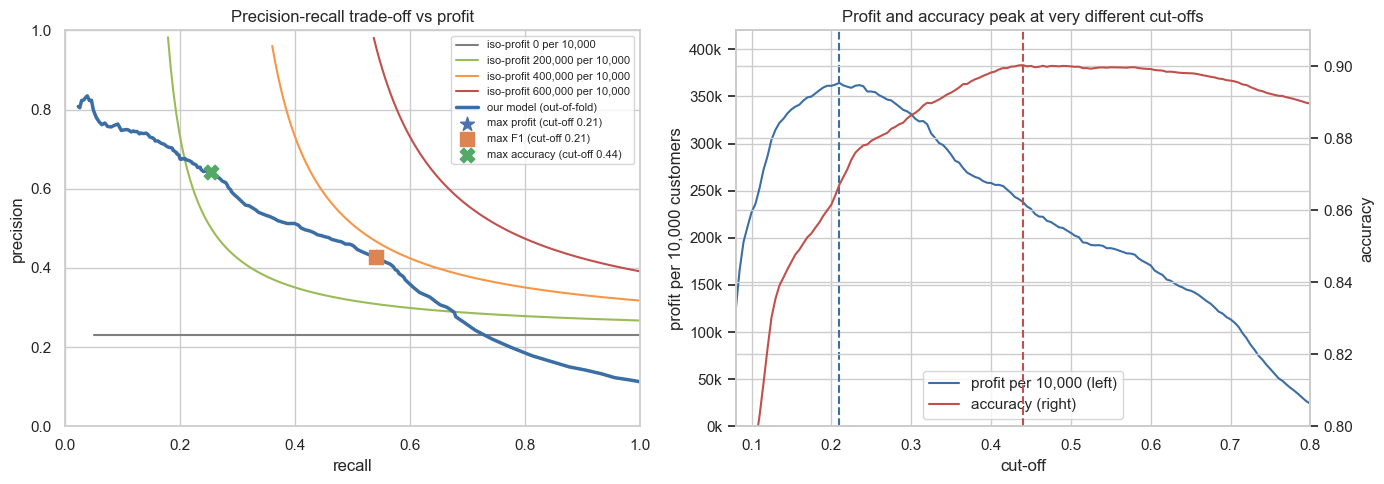

,cutoff,precision,recall,accuracy,f1,profit
maximise profit,0.21,0.428,0.541,0.867,0.478,364318.553
maximise F1,0.21,0.428,0.541,0.867,0.478,364318.553
maximise accuracy,0.44,0.642,0.254,0.900,0.364,237914.013


In [48]:
bt = balance_table(y_tr, oof)                                        # out-of-fold, training data only
best_profit = bt.loc[bt.profit.idxmax()]; best_f1 = bt.loc[bt.f1.idxmax()]; best_acc = bt.loc[bt.accuracy.idxmax()]
Rg = np.linspace(0.05,1.0,200)
fig, ax = plt.subplots(1,2, figsize=(14,5))
for tgt,col in [(0,'#7f7f7f'),(200_000,'#9bbb59'),(400_000,'#f79646'),(600_000,'#c0504d')]:
    pr = np.array([required_precision(r,tgt, prevalence=y_tr.mean()) for r in Rg]); ax[0].plot(Rg, pr, c=col, label=f'iso-profit {tgt:,.0f} per 10,000')
ax[0].plot(bt.recall, bt.precision, c='#3b6ea5', lw=2.5, label='our model (out-of-fold)')
for lab,row,m_ in [('max profit',best_profit,'*'),('max F1',best_f1,'s'),('max accuracy',best_acc,'X')]: ax[0].scatter(row.recall,row.precision,s=110,marker=m_,zorder=5,label=f'{lab} (cut-off {row.cutoff:.2f})')
ax[0].set_ylim(0,1); ax[0].set_xlim(0,1); ax[0].set_xlabel('recall'); ax[0].set_ylabel('precision'); ax[0].set_title('Precision-recall trade-off vs profit'); ax[0].legend(fontsize=8, loc='upper right')
a2 = ax[1]; a2.plot(bt.cutoff, bt.profit, c='#3b6ea5', label='profit per 10,000 (left)'); a2.set_xlabel('cut-off'); a2.set_ylabel('profit per 10,000 customers'); a2.set_xlim(0.08,0.8); a2.set_ylim(0,420_000); a2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f'{v/1e3:,.0f}k'))
a3 = a2.twinx(); a3.plot(bt.cutoff, bt.accuracy, c='#c0504d', label='accuracy (right)'); a3.set_ylabel('accuracy'); a3.set_ylim(0.80,0.91)
a2.axvline(best_profit.cutoff, c='#3b6ea5', ls='--'); a3.axvline(best_acc.cutoff, c='#c0504d', ls='--'); a2.set_title('Profit and accuracy peak at very different cut-offs')
h1,l1 = a2.get_legend_handles_labels(); h2,l2 = a3.get_legend_handles_labels(); a2.legend(h1+h2, l1+l2, loc='lower center'); plt.tight_layout(); plt.show()

summary = pd.DataFrame([best_profit, best_f1, best_acc], index=['maximise profit','maximise F1','maximise accuracy']).drop(columns=[])
display(summary[['cutoff','precision','recall','accuracy','f1','profit']].round(3))

### What this tells us
- **Maximising accuracy** picks a high cut-off (≈ 0.44): it wants to be right on the 89% non-buyers, so it gives *high precision (0.64) but low recall (0.25)* and earns about **238k, roughly a third less** than the profit-optimal point (≈ 364k per 10,000). It is the wrong yardstick because it treats a missed 1,001 sale and a wasted 300 call as equal mistakes.
- **Maximising profit** lands at cut-off ≈ 0.21: **precision ≈ 0.43, recall ≈ 54%**, comfortably above the 23% break-even. Its accuracy (≈ 0.867) is *lower* than the accuracy-maximising point (0.90). That is correct behaviour, not a flaw.
- **Maximising F1** (cut-off ≈ 0.235) happens to land very close to the profit optimum here (≈ 362k vs 364k). That is partly luck of the 1,001 / 300 ratio: F1 weights precision and recall equally, so if the economics were more lopsided, F1 would drift away from the profit-optimal point. Do not rely on it as a shortcut.
- **Rule of thumb for the client:** keep precision above ≈ 23% (otherwise stop dialling), then push recall as high as that constraint allows. At precision P, one extra point of recall is worth about `π·n·[V − c·(1/P − 1)] / 100`; at P = 0.46 that is ≈ 11.2 buyers × 649 ≈ **7,300 per 10,000 customers**.

### What-if: how the break-even moves when the economics move
Finance numbers change (cheaper calls, richer products). The break-even precision is the quickest read of how forgiving the campaign is.

,sale value 500,sale value 750,sale value 1001,sale value 1250,sale value 1500
call cost 150,0.231,0.167,0.130,0.107,0.091
call cost 200,0.286,0.211,0.167,0.138,0.118
call cost 300,0.375,0.286,0.231,0.194,0.167
call cost 400,0.444,0.348,0.286,0.242,0.211
call cost 500,0.500,0.400,0.333,0.286,0.250


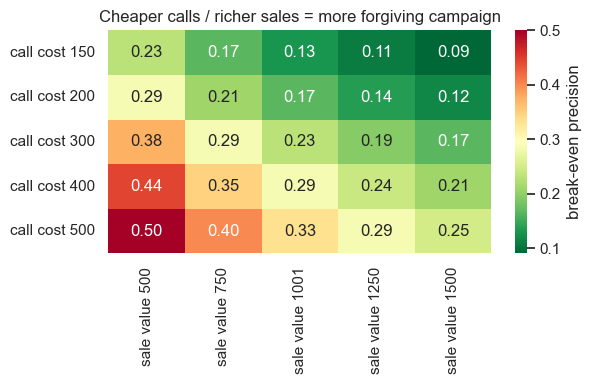

In [49]:
costs = [150,200,300,400,500]; vals = [500,750,1001,1250,1500]
wi = pd.DataFrame([[breakeven_precision(v,c_) for v in vals] for c_ in costs], index=[f'call cost {c_}' for c_ in costs], columns=[f'sale value {v}' for v in vals])
display(wi.round(3))
plt.figure(figsize=(6.2,4)); sns.heatmap(wi, annot=True, fmt='.2f', cmap='RdYlGn_r', cbar_kws={'label':'break-even precision'}); plt.title('Cheaper calls / richer sales = more forgiving campaign'); plt.tight_layout(); plt.show()

**How to use the functions in an interview or at work**
- `campaign_economics(precision, recall)`: "if the data science team promises P and R, what is the money and accuracy?"
- `required_precision(recall, target)` / `required_recall(precision, target)`: "what must the model reach to hit a profit target?"
- `balance_table(y, p)`: "where on the model's own trade-off curve should we operate?"
- `breakeven_precision(V, c)`: "below what precision should we stop calling?" (re-run whenever Finance updates V or c.)

---
# Stage 7: Summary, answers to the case questions, and limitations

### 7.1 One-paragraph summary
I built a regularised logistic-regression response model on the **14 inputs available *before* a call** (call duration is excluded as leakage). It ranks customers with **test AUC ≈ 0.80 (Gini ≈ 0.60, KS ≈ 0.50)**, is well-calibrated, and calling only customers whose predicted probability exceeds the **break-even 23%** captures about **half of all buyers by calling ≈ 13% of the list**, a lift of ≈ 4×. Applied to a 10,000-record list it yields an **expected net profit of ≈ 380,000** (calling everyone would lose ≈ 1.5 million), with ≈ 745,000 of potential profit lost to misclassification, most of it missed buyers.

### 7.2 The case study's questions, answered
| # | Question | Where | Short answer |
|---|---|---|---|
| 1 | Are all inputs relevant? | 1, 2, 3.1 | No. Call duration is leakage; home loan, personal loan and weekday are noise (IV ≈ 0). |
| 2 | What does the data look like; outliers/corrections? | 1 | Clean (no missing). Fixes: 11 duplicates, 999 sentinel → flag, cap call attempts at 10, rare levels pooled. |
| 3 | Discriminating power? | 2 | Information Value + univariate AUC, computed on train only. |
| 4 | Control high correlations? | 2, 3.6 | Correlation matrix + VIF; keep one of the three near-identical macro variables (VIFs 32-64 → < 3). |
| 5 | Do class imbalances matter? | 3.5 | For metrics and the cut-off, yes; for training, no resampling (it would distort probabilities). Stratified splits + AUC/PR-AUC/profit. |
| 6 | Different scales? | 3.4 | Standardise for logistic regression (regularisation); trees don't care. |
| 7 | Encode / group categoricals? | 3.2 | One-hot (nominal data); levels < 1% pooled, learned on train. |
| 8 | Bin numerics? | 3.3 | No: +0.0004 AUC, not worth the complexity. |
| 9 | Split for train/test? | 2.1, 3.8 | Yes: stratified 70/30 *before* any target-aware step; test touched once. |
| 10 | Validate while training? | 3-5 | 5-fold stratified CV; preprocessing refit inside each fold. |
| 11 | Which model is best? | 4.2, 5.1-5.2 | Pre-agreed criteria + 1-SE rule: simplest model within noise of the best, i.e. logistic. |
| 12 | Over/under-fit? | 4.3-4.4, 5.4 | Train-vs-validation gaps, depth curve, learning curve, hold-out test, calibration. |
| 13 | Variable importance? | 5.9 | Permutation importance + odds ratios; macro (employment variation) dominates. |
| 14 | Fit different models; which to optimise? | 4, 5.1 | Logistic, tree, forest, boosting; equal tuning effort; chosen by rule, not by taste. |
| 15 | How optimise, and why? | 5.3 | Grid over penalty × C, AUC scoring, stratified CV: regularisation controls bias-variance. |
| 16 | Cut-off? | 5.6 | Break-even from the profit table = 0.2306, confirmed on out-of-fold data. |
| 17 | Confusion matrix? | 5.8 | TP/FP/FN/TN explained in business terms; why accuracy is the wrong yardstick. |
| Bonus | Profit and lost opportunity | 6 | ≈ 380k net profit; ≈ 745k lost to misclassification (≈ 537k missed buyers + ≈ 208k wasted calls). |
| Extension | What precision/recall/accuracy does profit require? | 6B | Break-even precision 23.1% at any recall; profit-optimal point ≈ 0.43 precision / ≈ 54% recall; accuracy-max earns ~⅓ less. Reusable functions provided. |

### 7.3 Limitations & what I would do next (honest list)
1. **Macro variables act as a calendar.** The model's strongest driver is the economic cycle. This is excellent in-sample, but if conditions on the new list differ from the development period the lift may shrink. Next: out-of-time validation (needs the call dates) and monitoring of the score distribution (PSI) after launch.
2. **Random, not time-based, split.** If rows span different quarters, a random split slightly flatters the model. A time-based hold-out would be more honest for deployment.
3. **Prevalence on the new list.** A purchased prospect list probably converts differently than the development sample. Recalibrate or run a small pilot before committing the full budget.
4. **Masked categories.** Category labels are anonymised (e.g. `Cat_3_h***l`), so I can say which levels matter but not interpret them in plain language.
5. **Profit inputs are given, not estimated.** The 1,001 expected sale value rests on the Finance table and the risk-band mix; the cut-off moves if either changes (re-compute `t* = 300 / (sale value + 300)`).
6. **`calls` (attempts)** includes the current call; a stricter "attempts *before* today" feature would be safer in production, and the model loses almost nothing without it.
7. **Final deployment model** would be refit on train + test (all labelled data) with the same hyper-parameters; test metrics here are for the model fit on the 70% only.

### 7.4 Mentor's answer key to the open questions from Stage 2
**Q1. Why does keeping all of `ee_5 / em_8 / nd_9` hurt logistic regression more than a tree?**
In a linear model, each coefficient means "the effect of this variable *holding the others fixed*". When three variables move together (corr 0.91-0.97) there is almost no independent variation to estimate that from, so coefficients become unstable, their standard errors inflate, and signs can flip between samples, even though *predictions* stay fine. Trees pick one variable per split, so predictions are barely affected; the problem shows up as *importance being split arbitrarily* between the twins. We saw the proof in 3.6: using all three added nothing.

**Q2. `pd_19` has IV 0.54: leakage or legitimate?**
Legitimate. Leakage is about **availability at decision time** and **causal order**, not about how high the IV is. The outcome of the *previous* campaign is recorded before we ever pick up the phone this time, so it is a valid input. A "too good" IV is a prompt to *investigate*, not proof of a problem. Call duration failed that test (it is only known after the call); `pd_19` passed it.

**Q3. Drop `hd_14` / `ld_15` outright, or keep them "just in case"?**
Drop. I tested both: adding them back changed CV AUC by less than 0.001 (3.7). Fewer variables mean simpler data collection, less to monitor, and less chance of spurious relationships. A regularised model *could* have tolerated them, but "just in case" is not a reason when an experiment says there is no benefit. The exception would be a business or regulatory requirement to consider them.

### 7.5 How to compare with your own solution
Check whether you: (1) spotted the call-duration leakage; (2) split before selecting variables; (3) handled the 999 sentinel; (4) used a metric other than accuracy; (5) derived the cut-off from the profit table rather than 0.5; (6) kept the test set untouched; (7) set up the bonus as TP×sale-profit − FP×300, with FN as the lost opportunity. If your numbers differ, the most likely reasons are the feature set, the cut-off rule, and how the 10,000-list percentages were taken (test vs training). Each is explained above, so you can see exactly where we diverge.